# MTDome Louver Drive Health — stop-position drift, actuator parallelism, torque & current

**Question.** Louver actuator pairs have on a few occasions lost synchronisation and jammed. Is there drift in the
stopped open/closed positions, in the synchronisation of the two actuators, or in drive torque / current that
would flag a louver *before* it fails?

**Data.** `lsst.sal.MTDome.louvers` (≈0.7 Hz), `logevent_louversMotion`, `logevent_louversEnabled` (fault codes),
`logevent_brakesEngaged` and the louver commands / operational-mode events,
2025-09 → 2026-11-08, from the EFD caches written by [build_louver_health.py](build_louver_health.py).

**Telemetry layout** (from `ts_xml` `Louver` enum and verified on the data):

| array index | 2 | 11 | 12 | 20 | 21 | 29 |
|---|---|---|---|---|---|---|
| louver | B1 | E1 | E2 | H1 | H2 | M1 |
| drives A / B | 4 / 5 | 22 / 23 | 24 / 25 | 40 / 41 | 42 / 43 | 58 / 59 |

* Louver *i* has two actuators, drives `2i` (A) and `2i+1` (B), each with its own absolute encoder
  (`encoderHeadCalibrated`). Only these six louvers have ever been commanded or report non-zero telemetry.
* `positionActual{i}` is **exactly the mean of the two drive encoders** (−0.0088 %/count each, i.e. ~57 counts per 1 %).
  A desynchronisation between the two actuators is therefore *invisible* in `positionActual` — it lives in
  **A − B encoder offset**, which is what the controller's *"Parallelism between the two actuators … went over the
  maximum threshold"* fault (code 550001) watches.
* `driveTemperature` is always 0 (not reported).

**Metrics per stroke** (one row per louver per physical move):
stop position, A−B offset at rest before/after, maximum A−B excursion during the stroke, A vs B stroke length,
**drive-B onset lag** (how far B trails A in the first ~3 s of a move, after removing each louver's fixed
encoder-scale mismatch), mean/peak |torque| and current per drive, torque tracking error, stroke duration.

## Key findings (2026-11-08; drive-B enable / brake check §1.6 added 2026-11-13)

**Last night — B1 (index 2, drives 4/5) jammed at ~96 % open for ~6 h; recovered by on-site work, closed and re-synchronised by 14:51 UTC.**

| UTC | event |
|---|---|
| 11-07 23:30 | normal open stroke to 96.55 % (30 s, torque 4.7 Nm, A−B excursion 11.4 counts — largest of the prior 2 weeks, typical ~10.3) |
| **11-08 02:02** | **B1 "drives in fault" (002) while parked** — no motion, no torque; the first symptom |
| 08:36 | end-of-night close: E1/H1 close normally, B1 goes straight to ERROR |
| 08:50:22 | retry close: **drive A moves 66 counts (1.2 %) toward closed, drive B's encoder does not change at all** → parallelism fault (001) 1.6 s later |
| 08:53 / 09:03 / 09:16 / 13:17 | further retries: both drives ramp to the 12 Nm limit (3.7 A), A creeps ≤4 counts, B reads *exactly* constant → torque-saturated (004) each time |
| 13:08–13:22 | B encoder steps +3 counts, local-box e-stop pressed — on-site intervention |
| 13:26–14:51 | no louver telemetry (85 min gap) |
| 14:51 | B1 reports **closed (−0.03 %)**, A−B offset 8135.57 vs 8135.73 before the incident → actuators re-synchronised |

1. **Failure signature: the drive-B side doesn't move.** In all three 2026 parallelism faults (B1 2026-02-18,
   E1 2026-06-19/20, B1 2026-11-08), drive A moves ~65–75 counts while the B (odd-index) drive's encoder is frozen,
   in either direction. Drive B is **electrically enabled and pushing**: it draws 1.8–3.75 A, like A, and its torque
   follows its command up to 12 Nm. Even so, its end of the blade stays exactly still, and B1's
   brake-release *was* commanded on the failed 11-08 retries (§1.6). That points to **drive B's brake not opening
   physically, or a jam in the B actuator**, rather than a missing enable or a gradual bind. The Nov–Dec 2025 faults
   (H1, M1, E1) were a different mode: both drives moving, with A slowly outrunning B by ~10–20 counts (§1.4).
   Stop-position drift (`positionActual`) can't see either mode, because it is the mean of the two encoders.
2. **The usable early warning was an isolated single-louver drive fault while parked.** All four single-louver
   parallelism faults since 2025-11-28 were preceded by "drives of louvers *X* in fault" on that same louver,
   1.3–8.7 h earlier: M1 11-28 (1.3 h), B1 02-18 (8.7 h), E1 06-19 (6 h), **B1 last night 02:02 → 08:50 (6.8 h)**.
   It is not sufficient on its own — excluding H1, about half of such episodes did not progress (e.g. B1 Mar 30–Apr 3,
   E1 Jan 21–22), and H1 throws them routinely (~20 episodes, none progressed) — but it is the clearest flag in the
   data: after an isolated drive fault on B1/E1/M1, check drive-B enable / brake release before the next move.
3. **B1 showed no gradual telemetry trend** — its actuator parallelism is the tightest of the six (~10 counts), its
   drive-B onset lag is flat and torque/current are normal. Minor hints only: repeated 30 s `setLouvers` re-sends push
   it into the open hard stop (~99.1 %) with 7–11 Nm pulses that twist the blade ~5 counts (10-29, 11-06).

**Longer-term trends (all six louvers, Dec 2025 → Nov 2026):**

4. **E1 has a genuine precursor-type trend: drive-B onset lag has grown steadily** — scale-corrected excess lag
   ~0 → 5–8 counts in both directions, and its in-stroke A−B excursion ~32 → 39–40 counts (closing). E1 faulted in
   June and the trend continued afterwards. **E1 is the louver to watch next**; H1 (excursion 31 → 35, most drive-fault
   days) second.
5. **Stop positions drift only slightly.** Closed stop creeps ~−0.04 to −0.09 % over the year (E1 largest, −0.05 → −0.14 %);
   open stop drops ~0.3–0.9 % on *all* louvers together with a seasonal look (high Dec–Feb, low Jun–Oct) — a common-mode
   effect rather than a single-louver symptom. Encoder A−B offset at rest is stable to ~±1 count except **E1, which
   stepped −4 to −6 counts after its June fault**.
6. **Torque and current rise slowly and in common mode**: mean stroke torque +6–10 %, current +3–5 %, closing duration
   31.1 → 32.6 s (M1 34.2 s) since Dec 2025, with October highest. Because all six move together this looks
   environmental (temperature / lubrication) rather than one failing actuator; no louver stands out.

## Setup

In [1]:
import re
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import theilslopes
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA = pathlib.Path("data")
TAG = "20250901_20261108"

ACTIVE = [2, 11, 12, 20, 21, 29]
NAME = {2: "B1", 11: "E1", 12: "E2", 20: "H1", 21: "H2", 29: "M1"}
NAMES = [NAME[i] for i in ACTIVE]

# Offsets/stops were re-zeroed around 2025-12-01 after the Nov 2025 fault cluster; trends start here.
BASELINE_START = pd.Timestamp("2025-12-05", tz="UTC")

# Plot style (reference palette): drive A / drive B, fault markers in status red
C_A, C_B, C_GRAY, C_FAULT, C_TQSAT = "#2a78d6", "#eb6834", "#8a8984", "#e34948", "#eda100"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "lines.linewidth": 2,
})

In [2]:
# Caches written by build_louver_health.py (run it first to refresh: python3 -E build_louver_health.py)
moves_raw = pd.read_parquet(DATA / f"louver_moves_{TAG}.parquet")      # full-rate windows around each move group
events = pd.read_parquet(DATA / f"louver_events_{TAG}.parquet")         # logevent_louversMotion
enabled = pd.read_parquet(DATA / f"louver_enabled_{TAG}.parquet")       # logevent_louversEnabled (faultCode)
coarse = pd.read_parquet(DATA / f"louver_coarse_{TAG}.parquet")         # 10-min last(), all louvers
print(f"move windows: {len(moves_raw):,} samples in {moves_raw.move_group.nunique()} groups, "
      f"{moves_raw.index.min():%Y-%m-%d} → {moves_raw.index.max():%Y-%m-%d %H:%M}")
print(f"motion events: {len(events):,}   enabled/fault events: {len(enabled):,}   coarse rows: {len(coarse):,}")

move windows: 192,838 samples in 1087 groups, 2025-10-14 → 2026-11-08 13:19
motion events: 6,380   enabled/fault events: 1,940   coarse rows: 40,239


## Data preparation

### Fault codes

`logevent_louversEnabled.faultCode` is parsed into individual codes (the `55xxxx` / `5xxx` prefixes are the
same last-three-digit code): **001 = parallelism** between the two actuators over threshold, **002 = drives in fault**,
**003 = local-box e-stop**, **004 = torque saturated**. Republished duplicates are collapsed to the first occurrence per
(day, code, louver).

In [3]:
FAULT_LABEL = {1: "parallelism", 2: "drive fault", 3: "e-stop", 4: "torque saturated"}
rows = []
for t, fc in enabled.faultCode.items():
    for m in re.finditer(r"(\d{4,6})=([^,]*?)(?=, \d{4,6}=|$)", fc):
        code_ = int(m.group(1)) % 1000
        nms = sorted(set(re.findall(r"\b([A-N][123])\b", m.group(2))))
        for nm in nms:
            rows.append((t, code_, nm, len(nms) == 1))
faults_raw = pd.DataFrame(rows, columns=["t", "code", "louver", "solo"])   # solo: message names only this louver
faults_raw = faults_raw[(faults_raw.t.diff() > pd.Timedelta("30s")) | faults_raw.code.ne(faults_raw.code.shift())
                        | faults_raw.louver.ne(faults_raw.louver.shift())]   # drop rapid republishes
faults_raw["fault"] = faults_raw.code.map(FAULT_LABEL)
faults = faults_raw.copy()
faults["day"] = faults.t.dt.date
faults = faults.groupby(["day", "code", "louver"]).t.min().reset_index()
faults["fault"] = faults.code.map(FAULT_LABEL)

print("Fault-days per louver and type:")
display(faults.pivot_table(index="louver", columns="fault", values="day", aggfunc="count", fill_value=0).loc[NAMES])
print("Parallelism and torque-saturation faults:")
display(faults[faults.code.isin([1, 4])].sort_values("t")[["t", "louver", "fault"]].reset_index(drop=True))

par_faults = faults[faults.code == 1]
tq_faults = faults[faults.code == 4]

Fault-days per louver and type:


fault,drive fault,parallelism,torque saturated
louver,,,
B1,53,2,3
E1,54,3,1
E2,50,0,2
H1,59,1,5
H2,60,0,2
M1,60,2,2


Parallelism and torque-saturation faults:


,t,louver,fault
0,2025-11-25 18:23:15.938430+00:00,H1,parallelism
1,2025-11-28 16:59:17.899334+00:00,M1,parallelism
2,2025-12-01 11:25:52.422936+00:00,M1,parallelism
3,2025-12-01 12:12:24.012700+00:00,E1,parallelism
4,2025-12-01 18:00:25.912261+00:00,H1,torque saturated
5,2025-12-01 18:06:41.875395+00:00,B1,torque saturated
6,2025-12-01 18:06:42.785016+00:00,H2,torque saturated
7,2025-12-01 18:06:44.885397+00:00,E1,torque saturated
8,2025-12-01 18:06:44.885397+00:00,E2,torque saturated
9,2025-12-02 12:39:15.269879+00:00,H1,torque saturated


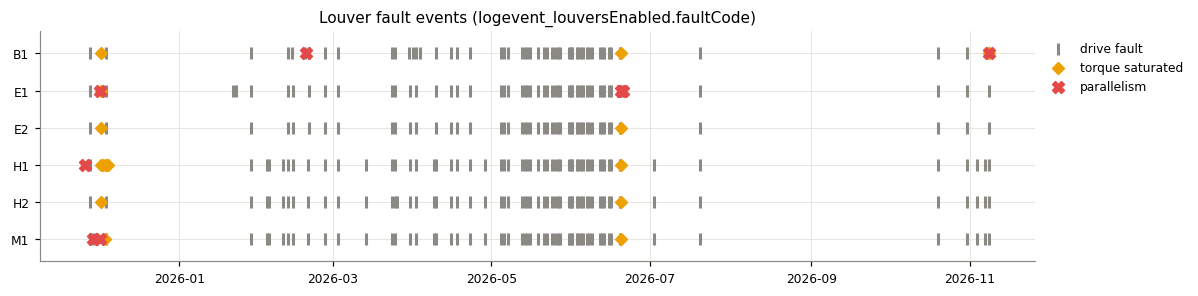

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.8))
style = {2: (C_GRAY, "|", 60), 4: (C_TQSAT, "D", 30), 1: (C_FAULT, "X", 60)}
for code_, (c, mk, s) in style.items():
    f = faults[faults.code == code_]
    ax.scatter(f.t, f.louver.map({n: k for k, n in enumerate(NAMES)}), color=c, marker=mk, s=s,
               label=FAULT_LABEL[code_], zorder=3)
ax.set_yticks(range(len(NAMES)), NAMES)
ax.set_ylim(-0.6, len(NAMES) - 0.4)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Louver fault events (logevent_louversEnabled.faultCode)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
fig.tight_layout()

### Per-stroke features

Each move-group window (30 s before the first `MOVING` state to 150 s after the last) is segmented per louver into
physical moves: contiguous samples with non-zero drive torque or position change. Rest values before/after are medians
of up to 3 / 10 quiet samples. Onset metrics use the encoder change from the sample before torque turns on to 2
samples after (≈3 s).

In [5]:
def segment_moves(df, i):
    a, b = 2 * i, 2 * i + 1
    out = []
    for gid, g in df.groupby("move_group", sort=False):
        g = g.sort_index()
        col = lambda k, j: g[f"{k}{j}"].to_numpy()
        p, cmd = col("positionActual", i), col("positionCommanded", i)
        ea, eb = col("encoderHeadCalibrated", a), col("encoderHeadCalibrated", b)
        tqa, tqb = col("driveTorqueActual", a), col("driveTorqueActual", b)
        tca, tcb = col("driveTorqueCommanded", a), col("driveTorqueCommanded", b)
        ia, ib = col("driveCurrentActual", a), col("driveCurrentActual", b)
        t = g.index
        moving = (np.abs(tqa) > 0.05) | (np.abs(tqb) > 0.05) | (np.r_[0, np.abs(np.diff(p))] > 0.05)
        if not moving.any():
            continue
        idx = np.flatnonzero(moving)
        brk = np.flatnonzero(np.diff(idx) > 2)              # allow 1-sample dropouts inside a move
        for s, e in zip(np.r_[idx[0], idx[brk + 1]], np.r_[idx[brk], idx[-1]]):
            pre = np.arange(max(0, s - 3), s)
            post = np.arange(e + 1, min(len(p), e + 11))
            post = post[~moving[post]]
            if len(pre) == 0 or len(post) < 3:
                continue
            m = np.arange(s, e + 1)
            d0 = np.median(ea[pre] - eb[pre])
            out.append(dict(
                louver=i, name=NAME[i], move_group=gid, t_start=t[s], t_end=t[e],
                duration_s=(t[e] - t[s]).total_seconds(),
                pos_from=np.median(p[pre]), pos_to=np.median(p[post]), cmd_to=cmd[e],
                offset_before=d0, offset_after=np.median(ea[post] - eb[post]),
                offset_dyn_max=np.max(np.abs(ea[m] - eb[m] - d0)),
                stroke_a=np.median(ea[post]) - np.median(ea[pre]),
                stroke_b=np.median(eb[post]) - np.median(eb[pre]),
                tq_mean_a=np.mean(np.abs(tqa[m])), tq_mean_b=np.mean(np.abs(tqb[m])),
                tq_peak_a=np.max(np.abs(tqa[m])), tq_peak_b=np.max(np.abs(tqb[m])),
                tq_err_a=np.sqrt(np.mean((tqa[m] - tca[m]) ** 2)),
                tq_err_b=np.sqrt(np.mean((tqb[m] - tcb[m]) ** 2)),
                cur_mean_a=np.mean(ia[m]), cur_mean_b=np.mean(ib[m]),
            ))
    return pd.DataFrame(out)


def onset_metrics(df, i, n=2):
    a, b = 2 * i, 2 * i + 1
    out = []
    for gid, g in df.groupby("move_group", sort=False):
        g = g.sort_index()
        ea, eb = g[f"encoderHeadCalibrated{a}"].to_numpy(), g[f"encoderHeadCalibrated{b}"].to_numpy()
        tqa, tqb = g[f"driveTorqueActual{a}"].to_numpy(), g[f"driveTorqueActual{b}"].to_numpy()
        on = (np.abs(tqa) > 0.05) | (np.abs(tqb) > 0.05)
        for s in np.flatnonzero(on & ~np.r_[False, on[:-1]]):     # rising edges of drive activity
            if s < 1 or s + n >= len(ea):
                continue
            out.append(dict(louver=i, name=NAME[i], t=g.index[s],
                            dA=ea[s + n] - ea[s - 1], dB=eb[s + n] - eb[s - 1],
                            tqa0=np.abs(tqa[s:s + n + 1]).max(), tqb0=np.abs(tqb[s:s + n + 1]).max()))
    return pd.DataFrame(out)


mv = pd.concat([segment_moves(moves_raw, i) for i in ACTIVE], ignore_index=True).sort_values("t_start")
mv["travel"] = mv.pos_to - mv.pos_from
mv["direction"] = np.where(mv.travel > 0.5, "open", np.where(mv.travel < -0.5, "close", "small"))
ok = mv.pos_from.between(-5, 105) & mv.pos_to.between(-5, 105) & (mv.stroke_a.abs() < 6000)   # drop ±300 % glitches
full = mv[ok & (mv.travel.abs() > 90)].copy()          # full strokes closed ↔ open
full["mismatch"] = full.stroke_a.abs() - full.stroke_b.abs()

on = pd.concat([onset_metrics(moves_raw, i) for i in ACTIVE], ignore_index=True)
on["lag"] = on.dA.abs() - on.dB.abs()                  # > 0: drive B behind drive A at onset (counts)
k_scale = (full.mismatch / full.stroke_a.abs()).groupby(full.name).median()   # fixed encoder-scale mismatch
on["excess_lag"] = on.lag - on.dA.abs() * on.name.map(k_scale)
on["direction"] = np.where(on.dA < 0, "open", "close")
on_ok = on[on.dA.abs() > 100]                          # real strokes, not end-stop pulses
stuck = on[(on.dA.abs() > 30) & (on.dB.abs() < 2)]     # drive B did not move at all

print(f"{len(mv):,} moves, {len(full):,} full strokes, {len(on_ok):,} stroke onsets")
display(full.groupby(["name", "direction"]).size().unstack())
print("Encoder-scale mismatch (|stroke A| − |stroke B|)/|stroke A|:", k_scale.round(4).to_dict())
print("\nOnsets where drive B did not move (|ΔA| > 30 counts, |ΔB| < 2):")
display(stuck[["name", "t", "dA", "dB", "tqa0", "tqb0"]].round(2).reset_index(drop=True))

8,988 moves, 3,655 full strokes, 7,363 stroke onsets


direction,close,open
name,,
B1,283,245
E1,391,338
E2,321,278
H1,358,313
H2,308,268
M1,291,261


Encoder-scale mismatch (|stroke A| − |stroke B|)/|stroke A|: {'B1': 0.0018, 'E1': 0.0054, 'E2': 0.0016, 'H1': 0.0058, 'H2': -0.001, 'M1': 0.0041}

Onsets where drive B did not move (|ΔA| > 30 counts, |ΔB| < 2):


,name,t,dA,dB,tqa0,tqb0
0,B1,2026-02-18 18:52:51.322735+00:00,-68.49,0.0,3.76,6.86
1,B1,2026-02-18 19:19:16.321929+00:00,64.71,0.0,4.12,0.07
2,B1,2026-02-18 19:20:22.291495+00:00,-65.75,0.0,3.78,8.93
3,B1,2026-02-18 19:22:00.208172+00:00,65.10,0.0,5.48,0.07
4,B1,2026-11-08 08:50:22.269901+00:00,66.18,0.0,1.05,0.84
5,E1,2026-06-19 19:52:54.190065+00:00,-74.50,0.0,0.38,0.18
6,E1,2026-06-19 21:13:37.850907+00:00,72.43,0.0,2.84,0.20
7,E1,2026-06-19 22:10:00.749823+00:00,-72.68,0.0,9.43,12.06
8,E1,2026-06-19 22:17:51.313399+00:00,71.95,0.0,5.00,0.26
9,E1,2026-06-19 22:21:00.551170+00:00,-71.35,0.0,0.13,0.24


### Plot helpers

In [6]:
def fault_lines(ax, name):
    for t in par_faults.loc[par_faults.louver == name, "t"]:
        ax.axvline(t, color=C_FAULT, lw=1.2, alpha=0.8, zorder=1)
    for t in tq_faults.loc[tq_faults.louver == name, "t"]:
        ax.axvline(t, color=C_TQSAT, lw=1, ls="--", alpha=0.8, zorder=1)


def roll(s, n=15):
    return s.rolling(n, center=True, min_periods=max(3, n // 3)).median()


def per_louver(df, ycols, title, ylabel, labels=None, colors=(C_A, C_B), tcol="t_start",
               since=BASELINE_START, ylim_q=(0.01, 0.99), n=15, sharey=False):
    # 6 small multiples (one per louver), raw points + rolling median per series, fault markers
    labels = labels or ycols
    fig, axs = plt.subplots(len(NAMES), 1, figsize=(11, 1.55 * len(NAMES) + 0.6), sharex=True, sharey=sharey)
    d = df[df[tcol] >= since] if since is not None else df
    for ax, nm in zip(axs, NAMES):
        x = d[d.name == nm].sort_values(tcol)
        vals = []
        for yc, lab, c in zip(ycols, labels, colors):
            xs = x[[tcol, yc]].dropna()
            ax.plot(xs[tcol], xs[yc], ".", ms=2.5, color=c, alpha=0.25)
            r = roll(xs[yc], n).where(~(xs[tcol].diff() > pd.Timedelta("20D")))   # break line across data gaps
            ax.plot(xs[tcol], r, color=c, lw=1.8, label=lab)
            vals.append(xs[yc])
        v = pd.concat(vals).dropna()
        if len(v) and ylim_q:
            lo, hi = v.quantile(ylim_q[0]), v.quantile(ylim_q[1]); pad = 0.15 * (hi - lo + 1e-9)
            ax.set_ylim(lo - pad, hi + pad)
        fault_lines(ax, nm)
        ax.set_ylabel(nm, rotation=0, ha="right", va="center", fontsize=10)
    axs[0].set_title(f"{title}   [{ylabel}]", loc="left")
    handles = axs[0].get_legend_handles_labels()
    extra = [plt.Line2D([], [], color=C_FAULT, lw=1.2, label="parallelism fault"),
             plt.Line2D([], [], color=C_TQSAT, lw=1, ls="--", label="torque saturated")]
    axs[0].legend(handles=handles[0] + extra, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.tight_layout()
    return fig, axs

## 1. Last night: B1 failure, 2026-11-07/08

Continuous full-rate telemetry for B1 (drives 4 = A, 5 = B) from the evening open to 15:00 UTC
(`louver_B1_20261108.parquet`), with the motion states and fault codes.

In [7]:
b1n = pd.read_parquet(DATA / "louver_B1_20261108.parquet").sort_index()
T0N, T1N = pd.Timestamp("2026-11-07 23:25", tz="UTC"), pd.Timestamp("2026-11-08 15:00", tz="UTC")
STATE = {1: "ERROR", 5: "MOVING", 13: "STOPPED_BRAKED", 20: "DISABLING_MOTOR_POWER", 23: "ENABLING_MOTOR_POWER",
         52: "DISABLED", 54: "ENABLED"}
st = events.loc[T0N:T1N, ["state2", "inPosition2"]]
st = st[st.state2.ne(st.state2.shift())].assign(state=lambda d: d.state2.map(STATE))
fb1 = faults_raw[(faults_raw.t.between(T0N, T1N)) & (faults_raw.louver == "B1")]
tl = pd.concat([st[["state"]].rename(columns={"state": "event"}).assign(kind="motion state"),
                fb1.set_index("t")[["fault"]].rename(columns={"fault": "event"}).assign(kind="fault")]).sort_index()
tl = tl[~(tl.index.duplicated(keep="first") & (tl.kind == "motion state"))]
cmd = b1n.positionCommanded2
print("B1 position-command changes:", [(f"{t:%m-%d %H:%M:%S}", int(v)) for t, v in cmd[cmd.ne(cmd.shift())].items()])
display(tl)

B1 position-command changes: [('11-07 23:25:00', 0), ('11-07 23:30:38', 100), ('11-08 08:36:31', 0), ('11-08 09:01:07', 100), ('11-08 09:03:45', 0), ('11-08 12:28:48', -1), ('11-08 12:29:33', 0), ('11-08 13:08:45', -1), ('11-08 13:09:21', 0)]


,event,kind
2026-11-07 23:30:38.388343+00:00,ENABLING_MOTOR_POWER,motion state
2026-11-07 23:30:39.878985+00:00,MOVING,motion state
2026-11-07 23:31:11.205123+00:00,STOPPED_BRAKED,motion state
2026-11-08 02:02:46.534938+00:00,drive fault,fault
2026-11-08 08:36:31.818837+00:00,ERROR,motion state
2026-11-08 08:49:25.081940+00:00,STOPPED_BRAKED,motion state
2026-11-08 08:50:22.270576+00:00,MOVING,motion state
2026-11-08 08:50:23.893595+00:00,parallelism,fault
2026-11-08 08:50:23.894020+00:00,ERROR,motion state
2026-11-08 08:52:24.952072+00:00,STOPPED_BRAKED,motion state


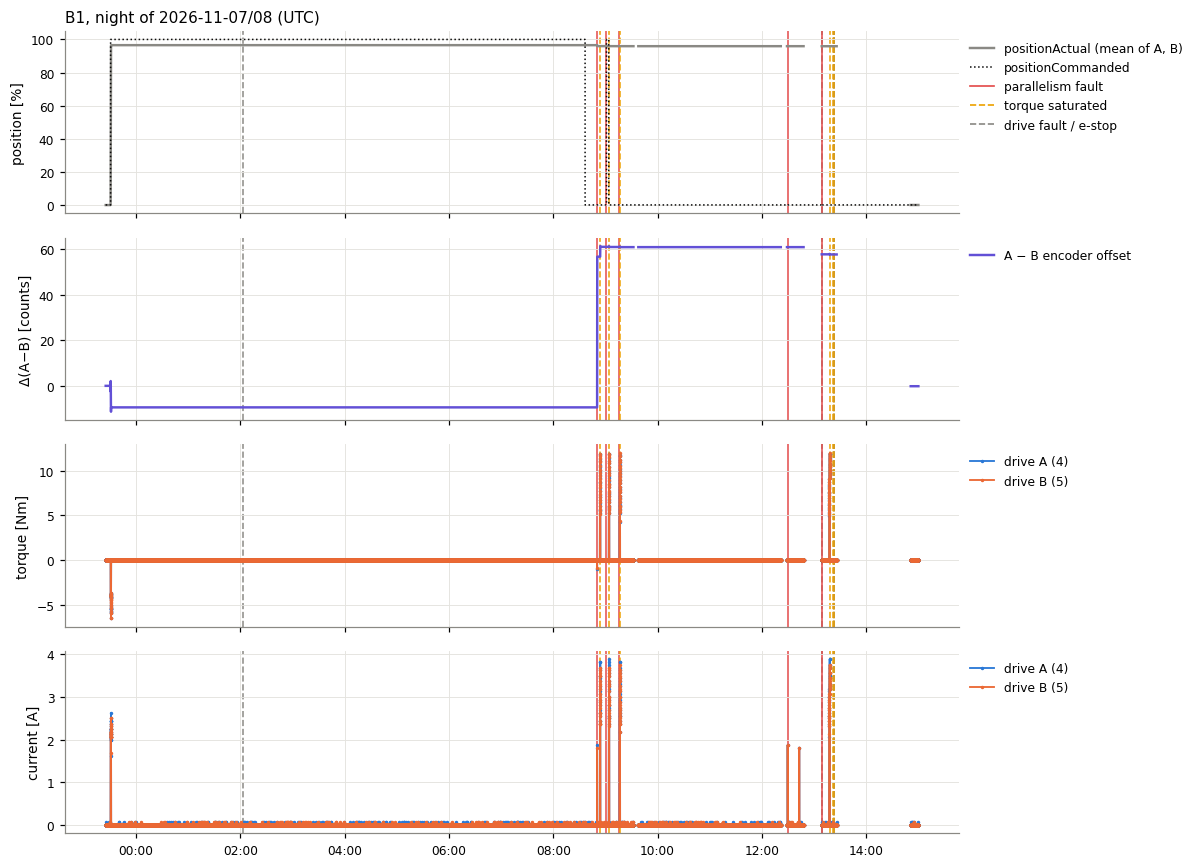

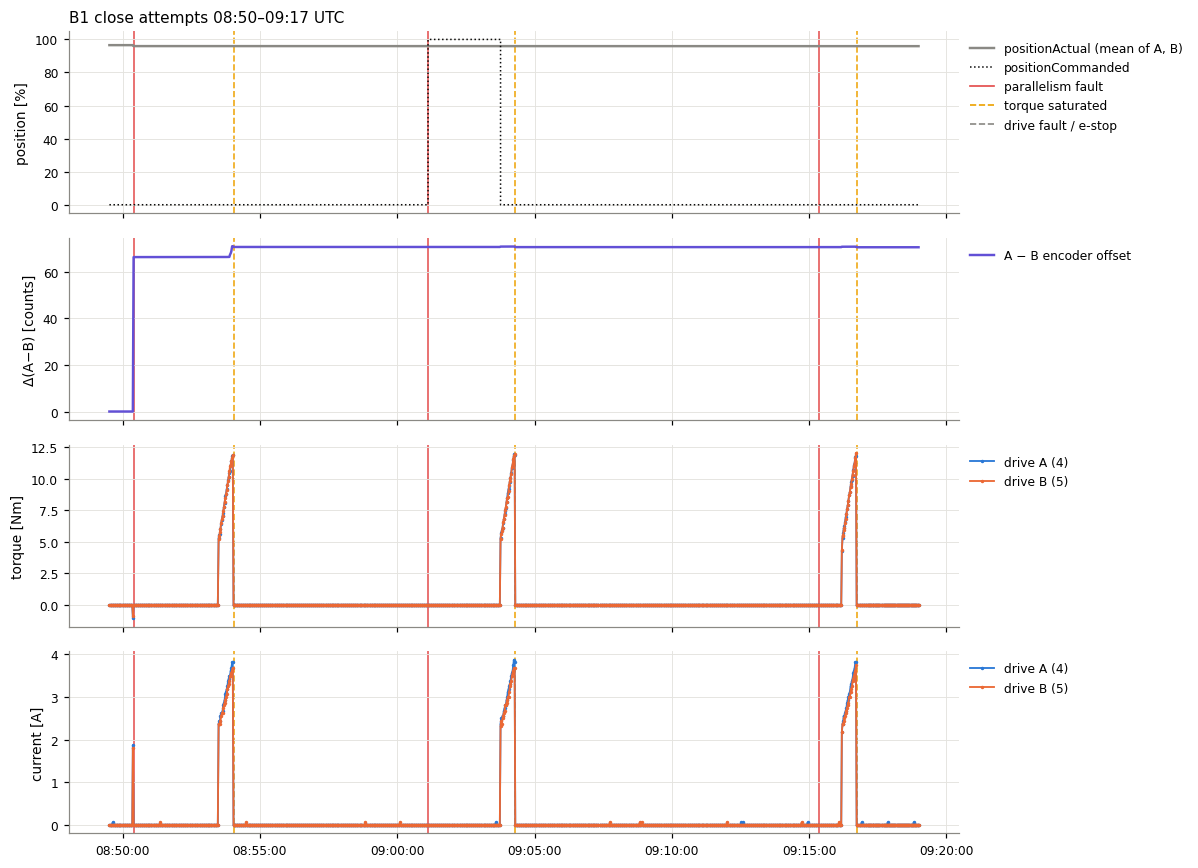

In [8]:
CNT2PCT = 0.0175   # % per encoder count
w = b1n.copy()
for j in (4, 5):
    w[f"trav{j}"] = -(w[f"encoderHeadCalibrated{j}"] - w[f"encoderHeadCalibrated{j}"].iloc[0]) * CNT2PCT
w["off"] = w.encoderHeadCalibrated4 - w.encoderHeadCalibrated5

def b1_panels(w, title, fmt):
    gaps = w.index.to_series().diff() > pd.Timedelta("60s")          # break lines across telemetry gaps
    if gaps.any():
        nan_rows = pd.DataFrame(np.nan, index=w.index[gaps] - pd.Timedelta("1s"), columns=w.columns)
        w = pd.concat([w, nan_rows]).sort_index()
    fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    axs[0].plot(w.index, w.positionActual2, color=C_GRAY, lw=1.6, label="positionActual (mean of A, B)")
    axs[0].step(w.index, w.positionCommanded2.where(w.positionCommanded2 >= 0), where="post", color="#0b0b0b",
                lw=1, ls=":", label="positionCommanded")
    axs[0].set_ylabel("position [%]")
    axs[1].plot(w.index, w.off - w.off.iloc[0], color="#6250d6", lw=1.6, label="A − B encoder offset")
    axs[1].set_ylabel("Δ(A−B) [counts]")
    for j, c, lab in [(4, C_A, "drive A (4)"), (5, C_B, "drive B (5)")]:
        axs[2].plot(w.index, w[f"driveTorqueActual{j}"], ".-", color=c, ms=2.5, lw=1.2, label=lab)
        axs[3].plot(w.index, w[f"driveCurrentActual{j}"], ".-", color=c, ms=2.5, lw=1.2, label=lab)
    axs[2].set_ylabel("torque [Nm]"); axs[3].set_ylabel("current [A]")
    for _, r in fb1.iterrows():
        c = {1: C_FAULT, 4: C_TQSAT}.get(r.code, C_GRAY)
        for ax in axs:
            if w.index.min() <= r.t <= w.index.max():
                ax.axvline(r.t, color=c, lw=1.1, ls="-" if r.code == 1 else "--", alpha=0.9, zorder=0)
    extra = [plt.Line2D([], [], color=C_FAULT, lw=1.1, label="parallelism fault"),
             plt.Line2D([], [], color=C_TQSAT, lw=1.1, ls="--", label="torque saturated"),
             plt.Line2D([], [], color=C_GRAY, lw=1.1, ls="--", label="drive fault / e-stop")]
    for k, ax in enumerate(axs):
        h = ax.get_legend_handles_labels()[0] + (extra if k == 0 else [])
        ax.legend(handles=h, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    axs[0].set_title(title, loc="left")
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter(fmt))
    fig.tight_layout()
    return fig

b1_panels(w, "B1, night of 2026-11-07/08 (UTC)", "%H:%M")
b1_panels(w.loc["2026-11-08 08:49:30":"2026-11-08 09:18"], "B1 close attempts 08:50–09:17 UTC", "%H:%M:%S");

### 1.1 What the drives did on each attempt

In [9]:
att = []
for t0 in st.index[st.state2 == 5].tolist() + [pd.Timestamp("2026-11-08 08:36:31", tz="UTC")]:
    x = b1n.loc[t0 - pd.Timedelta("3s"): t0 + pd.Timedelta("45s")]
    tq = x[["driveTorqueActual4", "driveTorqueActual5"]].abs()
    on_ = x[(tq > 0.05).any(axis=1)]
    pre = b1n.loc[:t0].iloc[-2]
    post = x.iloc[-1]
    att.append(dict(start=t0, cmd=int(x.positionCommanded2.iloc[-1]), pos_before=pre.positionActual2,
                    pos_after=post.positionActual2,
                    dA_counts=post.encoderHeadCalibrated4 - pre.encoderHeadCalibrated4,
                    dB_counts=post.encoderHeadCalibrated5 - pre.encoderHeadCalibrated5,
                    tq_max_A=tq.driveTorqueActual4.max(), tq_max_B=tq.driveTorqueActual5.max(),
                    cur_max_A=x.driveCurrentActual4.max(), cur_max_B=x.driveCurrentActual5.max(),
                    powered_s=(on_.index.max() - on_.index.min()).total_seconds() if len(on_) else 0.0))
display(pd.DataFrame(att).sort_values("start").round(3).reset_index(drop=True))

for lab, a_, b_ in [("parked 23:32→08:50", "2026-11-07 23:32", "2026-11-08 08:50:20"),
                    ("powered retries 08:53→13:08", "2026-11-08 08:53", "2026-11-08 13:08")]:
    x = b1n.loc[a_:b_]
    print(f"{lab:30s} encoder value changes: A = {int((x.encoderHeadCalibrated4.diff().abs() > 0).sum()):3d}, "
          f"B = {int((x.encoderHeadCalibrated5.diff().abs() > 0).sum()):3d}   ({len(x)} samples)")

,start,cmd,pos_before,pos_after,dA_counts,dB_counts,tq_max_A,tq_max_B,cur_max_A,cur_max_B,powered_s
0,2026-11-07 23:30:39.878985+00:00,100,-0.079,96.548,-5488.769,-5479.31,6.531,6.534,2.623,2.499,31.098
1,2026-11-08 08:36:31+00:00,0,96.548,96.548,0.000,0.00,0.000,0.000,0.000,0.000,0.000
2,2026-11-08 08:50:22.270576+00:00,0,96.548,95.966,66.181,0.00,1.050,0.836,1.872,1.810,0.000
3,2026-11-08 08:53:29.676687+00:00,0,95.966,95.928,4.341,0.00,11.886,11.880,3.813,3.683,30.916
4,2026-11-08 09:03:45.772225+00:00,0,95.928,95.928,-0.055,0.00,11.928,11.924,3.875,3.683,30.772
5,2026-11-08 09:16:11.593423+00:00,0,95.928,95.929,-0.061,0.00,11.760,12.034,3.813,3.751,30.924
6,2026-11-08 13:17:25.555939+00:00,0,95.901,95.902,-0.060,0.00,11.949,11.990,3.875,3.751,31.580


parked 23:32→08:50             encoder value changes: A =   0, B =   0   (22957 samples)
powered retries 08:53→13:08    encoder value changes: A =  75, B =   1   (9851 samples)


**Reading.**
* The open stroke at 23:30 was normal (both drives ~4–6 Nm, 30 s, A−B offset within its usual ~10-count stroke excursion).
* At **02:02** a *B1 drives in fault* event arrives while the louver is parked and braked — nothing moves, no torque.
* At 08:36 the end-of-night close sends B1 straight to ERROR (drive still faulted); E1/H1 close normally.
* After `exitFault` (08:49; no drive reset was sent, §1.6), the **08:50:22** close releases the brakes with ~1 Nm holding torque: **drive A's end drops 66 counts
  (1.2 %) toward closed in 1.6 s while drive B's encoder does not change** → parallelism trip.
* Each later retry ramps both drives to the 12 Nm torque limit (3.7 A). Drive A creeps 0.3–4 counts (the racked blade
  binding), **drive B's encoder never changes — exactly — for 4 h of powered retries** (1 change vs 57 for A) until on-site
  work at ~13:08. A drive that is really delivering 12 Nm into a bind shows some compliance, as A does; a perfectly
  frozen B reading, while drive B draws the same current as A and follows its torque command, means **B's end of the
  blade was physically held: its brake didn't open, or the B actuator jammed** (§1.6). B's `driveTorqueActual`
  follows the command, so it can't show whether B moved.
* Telemetry stops 13:26–14:51 (e-stop / on-site work). When it resumes B1 is closed (−0.03 %) and the A−B offset is
  back to its pre-incident value (8135.57 vs 8135.73 counts): the louver was recovered and re-synchronised during
  the gap (the EFD doesn't show how).

### 1.2 B1 history: was there a gradual warning?

Per-stroke metrics for B1 relative to its own history (full strokes since Dec 2025), with last night's open stroke
highlighted.

In [10]:
b1f = full[(full.name == "B1") & (full.t_start >= BASELINE_START)]
last = b1f[b1f.t_start < "2026-11-08 08:00"].iloc[-1]
mets = {"offset_dyn_max": "max A−B excursion [counts]", "mismatch": "|stroke A|−|stroke B| [counts]",
        "tq_mean_a": "mean |torque| A [Nm]", "tq_mean_b": "mean |torque| B [Nm]",
        "cur_mean_a": "mean current A [A]", "cur_mean_b": "mean current B [A]",
        "duration_s": "duration [s]", "pos_to": "stop position [%]"}
rows = []
for m, lab in mets.items():
    h = b1f[(b1f.direction == last.direction) & (b1f.t_start < last.t_start)][m]
    rows.append(dict(metric=lab, last_stroke=last[m], hist_median=h.median(), hist_p05=h.quantile(.05),
                     hist_p95=h.quantile(.95), percentile=(h < last[m]).mean() * 100))
print(f"Last B1 stroke before the jam: {last.direction} at {last.t_start:%Y-%m-%d %H:%M} UTC "
      f"(vs {len(h)} earlier {last.direction} strokes)")
display(pd.DataFrame(rows).round(2))

onb1 = on_ok[(on_ok.name == "B1") & (on_ok.t >= BASELINE_START)]
print("B1 drive-B onset excess lag, last 10 strokes vs history (counts):")
display(pd.DataFrame({"last10": onb1.tail(10).set_index("t").excess_lag.round(2)}).T)
print(f"history: median {onb1.excess_lag.median():.2f}, p05 {onb1.excess_lag.quantile(.05):.2f}, "
      f"p95 {onb1.excess_lag.quantile(.95):.2f}")

Last B1 stroke before the jam: open at 2026-11-07 23:30 UTC (vs 203 earlier open strokes)


,metric,last_stroke,hist_median,hist_p05,hist_p95,percentile
0,max A−B excursion [counts],11.37,11.60,10.01,13.33,42.86
1,|stroke A|−|stroke B| [counts],9.46,10.20,8.93,11.58,23.65
2,mean |torque| A [Nm],4.71,4.68,4.33,5.09,53.69
3,mean |torque| B [Nm],4.64,4.65,4.28,5.02,48.77
4,mean current A [A],2.24,2.17,2.06,2.31,75.37
5,mean current B [A],2.18,2.12,2.02,2.24,78.33
6,duration [s],31.10,30.38,29.30,31.64,83.74
7,stop position [%],96.55,96.50,95.91,96.93,53.69


B1 drive-B onset excess lag, last 10 strokes vs history (counts):


t,2026-11-06 00:43:14.001641+00:00,2026-11-06 08:51:09.806797+00:00,2026-11-06 22:10:42.278725+00:00,2026-11-06 22:11:46.100307+00:00,2026-11-06 23:05:05.846180+00:00,2026-11-06 23:05:58.826222+00:00,2026-11-07 08:49:29.113404+00:00,2026-11-07 21:56:44.301683+00:00,2026-11-07 21:57:23.103011+00:00,2026-11-07 23:30:38.387659+00:00
last10,-0.2,-6.58,1.76,0.3,-0.77,-1.67,-8.17,0.57,-1.76,1.82


history: median -0.48, p05 -8.08, p95 2.75


### 1.3 Precursor: isolated single-louver drive faults

The 02:02 B1 drive fault came 6.8 h before the jam. Below: every episode of *drives in fault* (002) naming a single
louver (gaps < 48 h merged) and whether a parallelism fault on that louver followed within 72 h.

In [11]:
iso = faults_raw[(faults_raw.code == 2) & faults_raw.solo].sort_values("t")
ep = []
for nm, g in iso.groupby("louver"):
    eid = (g.t.diff() > pd.Timedelta("48h")).cumsum()
    for _, e in g.groupby(eid):
        t_last = e.t.max()
        nxt = faults_raw[(faults_raw.louver == nm) & (faults_raw.code == 1) & (faults_raw.t >= e.t.min())
                         & (faults_raw.t <= t_last + pd.Timedelta("72h"))]
        tp = nxt.t.min() if len(nxt) else pd.NaT
        before = e.t[e.t < tp] if len(nxt) else e.t
        ep.append(dict(louver=nm, first_drive_fault=e.t.min(), n=len(e), parallelism_fault=tp,
                       lead_h=(tp - before.max()).total_seconds() / 3600 if len(nxt) and len(before) else np.nan))
ep = pd.DataFrame(ep).sort_values("first_drive_fault").reset_index(drop=True)
display(ep.round(1))
print("lead_h = parallelism fault − last isolated drive fault before it")
display(ep.groupby("louver").agg(episodes=("n", "size"), followed_by_parallelism=("parallelism_fault", "count")).T)

,louver,first_drive_fault,n,parallelism_fault,lead_h
0,H1,2025-11-27 13:50:44.887787+00:00,3,NaT,NaN
1,M1,2025-11-28 15:37:14.715653+00:00,2,2025-11-28 16:59:17.899334+00:00,1.3
2,H1,2025-12-03 15:29:02.801175+00:00,1,NaT,NaN
3,E1,2026-01-21 11:38:21.763655+00:00,5,NaT,NaN
4,H1,2026-01-28 12:04:49.244940+00:00,1,NaT,NaN
5,B1,2026-02-13 09:47:21.431080+00:00,5,NaT,NaN
6,H1,2026-02-13 16:55:16.224340+00:00,1,NaT,NaN
7,B1,2026-02-18 04:29:25.474531+00:00,2,2026-02-18 18:52:52.491150+00:00,8.7
8,H1,2026-02-26 03:40:04.858239+00:00,1,NaT,NaN
9,H2,2026-03-25 18:40:53.123895+00:00,1,NaT,NaN


lead_h = parallelism fault − last isolated drive fault before it


louver,B1,E1,H1,H2,M1
episodes,5,2,19,1,1
followed_by_parallelism,2,1,0,0,1


**Reading.** All four single-louver parallelism faults since 2025-11-28 (M1 11-28, B1 02-18, E1 06-19, B1 11-08) were
preceded by an isolated drive fault on the same louver, 1.3–8.7 h earlier. The converse is weaker: excluding H1, about
half of the isolated drive-fault episodes went on to a parallelism fault; **H1 throws isolated drive faults routinely
(~20 episodes) and never progressed** — a separate chronic issue worth its own look. Operationally: an isolated
drive fault on B1, E1 or M1 should be treated as "check drive B enable / brake release before the next move".

### 1.4 Parallelism-fault signatures

Raw telemetry for parallelism-fault episodes: encoder change of each drive since the start of the window (converted
to %), and drive torque. The first column, M1 2025-11-28, is the late-2025 mode: both drives move and A slowly
outruns B. The other three are the 2026 mode: drive B (orange) stays flat while drive A moves ≈1.2 % and the
controller trips. The table below classifies every parallelism fault that has a cached full-rate window.

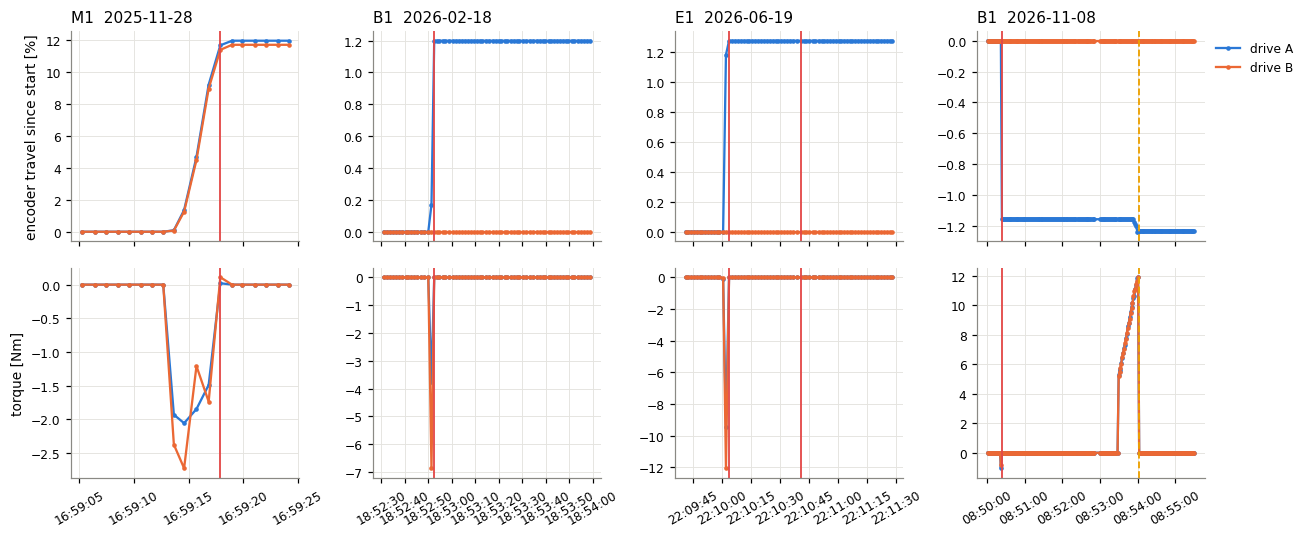

In [12]:
episodes = [("M1", "2025-11-28 16:59:05", "2025-11-28 16:59:25"),
            ("B1", "2026-02-18 18:52:30", "2026-02-18 18:54:00"),
            ("E1", "2026-06-19 22:09:40", "2026-06-19 22:11:30"),
            ("B1", "2026-11-08 08:50:00", "2026-11-08 08:55:30")]
CNT2PCT = 0.0175
fig, axs = plt.subplots(2, len(episodes), figsize=(12, 5), sharex="col")
for k, (nm, t0, t1) in enumerate(episodes):
    i = {v: kk for kk, v in NAME.items()}[nm]; a, b = 2 * i, 2 * i + 1
    w = moves_raw.loc[pd.Timestamp(t0, tz="UTC"):pd.Timestamp(t1, tz="UTC")].sort_index()
    for j, c, lab in [(a, C_A, "drive A"), (b, C_B, "drive B")]:
        e = w[f"encoderHeadCalibrated{j}"]
        axs[0, k].plot(w.index, -(e - e.iloc[0]) * CNT2PCT, ".-", color=c, ms=4, lw=1.5, label=lab)
        axs[1, k].plot(w.index, w[f"driveTorqueActual{j}"], ".-", color=c, ms=4, lw=1.5, label=lab)
    for _, f in faults_raw[(faults_raw.louver == nm) & faults_raw.code.isin([1, 4])].iterrows():
        for r in (0, 1):
            if w.index.min() <= f.t <= w.index.max():
                axs[r, k].axvline(f.t, color=C_FAULT if f.code == 1 else C_TQSAT, lw=1.2,
                                  ls="-" if f.code == 1 else "--")
    axs[0, k].set_title(f"{nm}  {t0[:10]}", loc="left")
    axs[1, k].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    axs[1, k].tick_params(axis="x", rotation=30)
axs[0, 0].set_ylabel("encoder travel since start [%]"); axs[1, 0].set_ylabel("torque [Nm]")
axs[0, -1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()

In [13]:
INV = {v: k for k, v in NAME.items()}
mr = moves_raw[~moves_raw.index.duplicated()].sort_index()
pf = faults_raw[faults_raw.code == 1].sort_values("t")
pf = pf[pf.groupby("louver").t.diff().fillna(pd.Timedelta("1D")) > pd.Timedelta("120s")]   # first trip of a burst
rows = []
for _, f in pf.iterrows():
    i = INV[f.louver]; a, b = 2 * i, 2 * i + 1
    w = mr.loc[f.t - pd.Timedelta("8s"): f.t + pd.Timedelta("1s")]
    if len(w) < 3:
        continue                                   # no full-rate window cached (e.g. retries with louver idle)
    on = w[(w[[f"driveCurrentActual{a}", f"driveCurrentActual{b}"]] > 0.5).any(axis=1)]
    dA = w[f"encoderHeadCalibrated{a}"].iloc[-1] - w[f"encoderHeadCalibrated{a}"].iloc[0]
    dB = w[f"encoderHeadCalibrated{b}"].iloc[-1] - w[f"encoderHeadCalibrated{b}"].iloc[0]
    if len(on) == 0:
        mode = "no motion (already out of parallel)"
    elif abs(dB) < 1 and abs(dA) > 30:
        mode = "drive B side frozen"
    elif abs(dB) > 30:
        mode = "both moving, A outruns B"
    else:
        mode = "other"
    rows.append(dict(t=f.t.floor("s"), louver=f.louver, mode=mode, dA=dA, dB=dB, dA_minus_dB=dA - dB,
                     iA_max=on[f"driveCurrentActual{a}"].max(), iB_max=on[f"driveCurrentActual{b}"].max(),
                     tcB_max=on[f"driveTorqueCommanded{b}"].abs().max(),
                     tqB_max=on[f"driveTorqueActual{b}"].abs().max()))
par_modes = pd.DataFrame(rows)
print("Parallelism faults with a cached full-rate window (encoder changes in counts over the 8 s before the trip;\n"
      "currents [A] and drive-B torque [Nm] while powered):")
display(par_modes.round(2))

Parallelism faults with a cached full-rate window (encoder changes in counts over the 8 s before the trip;
currents [A] and drive-B torque [Nm] while powered):


,t,louver,mode,dA,dB,dA_minus_dB,iA_max,iB_max,tcB_max,tqB_max
0,2025-11-25 18:23:15+00:00,H1,"both moving, A outruns B",-1396.36,-1378.13,-18.22,2.06,2.18,4.14,4.22
1,2025-11-28 16:59:17+00:00,M1,"both moving, A outruns B",-668.20,-652.06,-16.14,1.96,2.02,2.45,2.73
2,2025-11-28 17:04:39+00:00,M1,"both moving, A outruns B",-636.47,-619.21,-17.26,1.96,2.06,2.61,2.68
3,2025-12-01 11:25:52+00:00,M1,"both moving, A outruns B",-679.81,-661.11,-18.70,2.06,2.06,3.40,3.45
4,2025-12-01 12:37:58+00:00,E1,"both moving, A outruns B",-1477.52,-1469.18,-8.33,2.81,2.56,5.16,7.66
5,2025-12-01 12:58:12+00:00,M1,"both moving, A outruns B",-673.67,-657.10,-16.57,2.12,2.12,3.50,3.50
6,2026-02-18 18:52:52+00:00,B1,drive B side frozen,-68.49,0.00,-68.49,2.18,2.62,7.28,6.86
7,2026-02-18 19:20:23+00:00,B1,drive B side frozen,-65.75,0.00,-65.75,2.18,3.06,9.35,8.93
8,2026-06-19 19:52:55+00:00,E1,drive B side frozen,-74.50,0.00,-74.50,1.81,1.87,3.85,0.18
9,2026-06-19 22:10:03+00:00,E1,drive B side frozen,-72.68,0.00,-72.68,3.25,3.75,12.00,12.06


**Reading — two different modes.**
* **Nov–Dec 2025 (H1, M1, E1): both drives moving.** Both actuators run a normal-speed stroke and A slowly outruns B;
  the trip comes once the divergence reaches ~10–20 counts within the stroke, far below the 65–75 counts of the 2026
  trips. The trip level appears to have been raised between Dec 2025 and Feb 2026.
* **2026 (B1 02-18, E1 06-19, B1 11-08): the drive-B side does not move at all.** Drive A moves ~65–75 counts and B's
  encoder doesn't change by a single count. In every one of these trips, **drive B is electrically live**: it draws
  1.8–3.75 A, like A, and its actual torque follows its command (up to 12 Nm on E1 06-19). So the 2026 faults are not
  "drive B not enabled". The drive is powered and pushing, but its end of the blade doesn't move. See §1.6.

### 1.5 B1 in the two weeks before the jam

Moves after open commands to 100 % repeatedly push B1 into its open hard stop (~99.1 %) as `setLouvers` is re-sent every
30 s; each re-send pulses 7–11 Nm and the A−B offset steps by ~5 counts (one drive pushes further than the other).

In [14]:
b1 = mv[(mv.name == "B1") & (mv.t_start >= "2026-10-25")].copy()
b1["d_offset"] = b1.offset_after - b1.offset_before
cols = ["t_start", "direction", "pos_from", "pos_to", "cmd_to", "duration_s", "offset_after", "d_offset",
        "offset_dyn_max", "stroke_a", "stroke_b", "tq_mean_a", "tq_mean_b", "tq_peak_a", "tq_peak_b"]
display(b1[(b1.direction != "small") | (b1.tq_peak_a > 7) | (b1.d_offset.abs() > 2)][cols].round(2)
        .reset_index(drop=True))

,t_start,direction,pos_from,pos_to,cmd_to,duration_s,offset_after,d_offset,offset_dyn_max,stroke_a,stroke_b,tq_mean_a,tq_mean_b,tq_peak_a,tq_peak_b
0,2026-10-25 18:50:03.602504+00:00,open,-0.09,9.55,10,3.58,8132.08,-2.78,2.45,-548.72,-545.95,2.96,2.99,4.43,4.97
1,2026-10-25 18:50:22.246578+00:00,open,9.55,10.10,10,1.43,8133.11,1.02,1.02,-30.44,-31.47,1.67,1.53,3.34,3.06
2,2026-10-25 18:50:42.895545+00:00,close,10.10,-0.08,0,5.97,8134.84,1.73,2.77,578.42,576.69,3.73,3.83,5.67,6.03
3,2026-10-27 18:34:02.505678+00:00,open,-0.08,9.49,10,4.12,8132.15,-2.69,2.69,-544.26,-541.57,3.01,2.64,5.25,4.49
4,2026-10-27 18:34:22.809230+00:00,close,9.49,-0.08,0,5.90,8134.62,2.47,1.60,544.23,541.76,3.64,2.86,5.73,5.59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2026-11-08 08:50:22.269901+00:00,close,96.55,95.97,0,1.62,8192.45,66.18,66.18,66.18,0.00,0.52,0.43,1.05,0.84
62,2026-11-08 08:53:29.675490+00:00,small,95.97,95.93,0,30.92,8196.79,4.34,4.67,4.34,0.00,8.61,8.60,11.89,11.88
63,2026-11-08 09:03:45.771010+00:00,small,95.93,95.93,0,30.77,8196.73,-0.05,0.20,-0.05,0.00,8.65,8.63,11.93,11.92
64,2026-11-08 09:16:11.592328+00:00,small,95.93,95.93,0,30.92,8196.67,-0.06,0.19,-0.06,0.00,8.43,8.41,11.76,12.03


### 1.6 Was drive B enabled, and was the brake release issued? (added 2026-11-13)

Engineering asked whether drive B was effectively enabled, and whether its brake-release command was issued, during
the failed closing attempts. This section uses three sources:

* **`logevent_brakesEngaged.brakes`.** A bitmask where bit *n* = ts_xml `Brake` enum value *n*; `LOUVER_B1` = bit 7.
  The decoding checks out against the motion: the 23:30 open clears exactly the six motorized-louver bits, and the
  08:36 close clears five of them, all except B1.
* **The louver commands and operational-mode changes** (`louver_cmds_<tag>.parquet`).
* **Drive currents and torques** from the full-rate B1 cache.

A powered louver drive draws ≈2 A even at zero torque (both drives read 2.12 A at the start of the normal 23:30 open),
and a parked drive reads 0 A. So `driveCurrentActual` is a good indicator of whether a drive is enabled.

In [15]:
brakes = pd.read_parquet(DATA / f"louver_brakes_{TAG}.parquet").brakes.astype("int64")
cmds = pd.read_parquet(DATA / f"louver_cmds_{TAG}.parquet")
BRAKE_BIT = {"B1": 7, "E1": 16, "E2": 17, "H1": 25, "H2": 26, "M1": 34}      # ts_xml MTDome Brake enum value
b1_released = pd.Series(((brakes.to_numpy() >> BRAKE_BIT["B1"]) & 1) == 0, index=brakes.index)

rb = b1_released.loc[T0N:T1N]
rel_on = rb.index[rb.to_numpy() & ~np.r_[False, rb.to_numpy()[:-1]]]
rel_off = rb.index[~rb.to_numpy() & np.r_[False, rb.to_numpy()[:-1]]]
releases = pd.DataFrame({"released": rel_on,
                         "engaged": [rel_off[rel_off > t].min() for t in rel_on]})

lcs_mode = cmds[(cmds.kind == "operationalMode") & cmds.detail.str.endswith("subsys=8")].detail.str[5]
lcs_mode = lcs_mode.map({"1": "NORMAL", "2": "DEGRADED"})
OUTCOME = {1: "parallelism fault", 4: "torque saturated", 2: "drive fault", 3: "e-stop"}

rows = []
for tc in cmds.loc[T0N:T1N].query("kind == 'closeLouvers'").index:
    x = b1n.loc[tc - pd.Timedelta("3s"): tc + pd.Timedelta("45s")]
    pre = b1n.loc[:tc].iloc[-1]
    rel = releases[releases.released.between(tc, tc + pd.Timedelta("10s"))]
    f = faults_raw[(faults_raw.louver == "B1") & faults_raw.t.between(tc, tc + pd.Timedelta("45s"))]
    s2 = events.loc[tc: tc + pd.Timedelta("5s"), "state2"]
    powered = x[x.driveTorqueCommanded5.abs() > 1.0]
    rows.append({
        "close command": tc.floor("s").strftime("%H:%M:%S"),
        "LCS mode": lcs_mode.loc[:tc].iloc[-1] if len(lcs_mode.loc[T0N:tc]) else "NORMAL",
        "B1 brake released": rel.released.iloc[0].strftime("%H:%M:%S.%f")[:-4] if len(rel) else "no",
        "released for [s]": (rel.engaged.iloc[0] - rel.released.iloc[0]).total_seconds() if len(rel) else 0.0,
        "outcome": OUTCOME[f.code.iloc[0]] if len(f) else STATE.get(int(s2.iloc[0]), "?") if len(s2)
                   else "command failed, no motion",
        "ΔA [counts]": x.encoderHeadCalibrated4.iloc[-1] - pre.encoderHeadCalibrated4,
        "ΔB [counts]": x.encoderHeadCalibrated5.iloc[-1] - pre.encoderHeadCalibrated5,
        "I_A max [A]": x.driveCurrentActual4.max(), "I_B max [A]": x.driveCurrentActual5.max(),
        "|T_B| cmd max [Nm]": x.driveTorqueCommanded5.abs().max() if len(powered) else 0.0,
        "B torque tracking rms [Nm]": np.sqrt(((powered.driveTorqueActual5 - powered.driveTorqueCommanded5) ** 2)
                                              .mean()) if len(powered) else np.nan,
    })
attempts = pd.DataFrame(rows)
display(attempts.round(2))
resets_night = cmds.loc[T0N:T1N].query("kind in ['exitFault', 'resetDrivesLouvers']")
print("exitFault / resetDrivesLouvers during the night (reset lists drive indices; B1 = drives 4, 5):")
display(resets_night.assign(detail=resets_night.detail.replace("", "—")))

,close command,LCS mode,B1 brake released,released for [s],outcome,ΔA [counts],ΔB [counts],I_A max [A],I_B max [A],|T_B| cmd max [Nm],B torque tracking rms [Nm]
0,08:36:29,NORMAL,no,0.00,ERROR,0.00,0.0,0.00,0.00,0.00,NaN
1,08:50:20,NORMAL,08:50:22.27,1.62,parallelism fault,66.18,0.0,1.87,1.81,0.00,NaN
2,08:53:26,DEGRADED,08:53:29.67,32.60,torque saturated,4.34,0.0,3.81,3.68,12.00,0.09
3,09:03:42,DEGRADED,09:03:45.77,32.20,torque saturated,-0.05,0.0,3.88,3.68,12.00,0.08
4,09:15:19,NORMAL,no,0.00,parallelism fault,-0.00,0.0,0.00,0.00,0.00,NaN
5,09:16:09,DEGRADED,09:16:11.59,32.39,torque saturated,-0.06,0.0,3.81,3.75,11.99,0.16
6,12:29:31,NORMAL,no,0.00,parallelism fault,-0.00,0.0,1.87,1.87,0.00,NaN
7,12:40:27,NORMAL,no,0.00,"command failed, no motion",0.00,0.0,0.00,0.06,0.00,NaN
8,12:42:52,NORMAL,no,0.00,ENABLING_MOTOR_POWER,-0.00,0.0,1.81,1.81,0.00,NaN
9,13:09:19,NORMAL,no,0.00,parallelism fault,0.00,0.0,0.00,0.00,0.00,NaN


exitFault / resetDrivesLouvers during the night (reset lists drive indices; B1 = drives 4, 5):


,kind,detail
time,,
2026-11-08 01:14:01.972066+00:00,exitFault,—
2026-11-08 01:14:34.476875+00:00,exitFault,—
2026-11-08 08:49:21.420604+00:00,exitFault,—
2026-11-08 08:52:21.515530+00:00,exitFault,—
2026-11-08 08:55:31.049552+00:00,exitFault,—
2026-11-08 08:58:06.956530+00:00,exitFault,—
2026-11-08 09:01:57.049265+00:00,exitFault,—
2026-11-08 09:07:20.594232+00:00,exitFault,—
2026-11-08 09:15:54.416635+00:00,exitFault,—


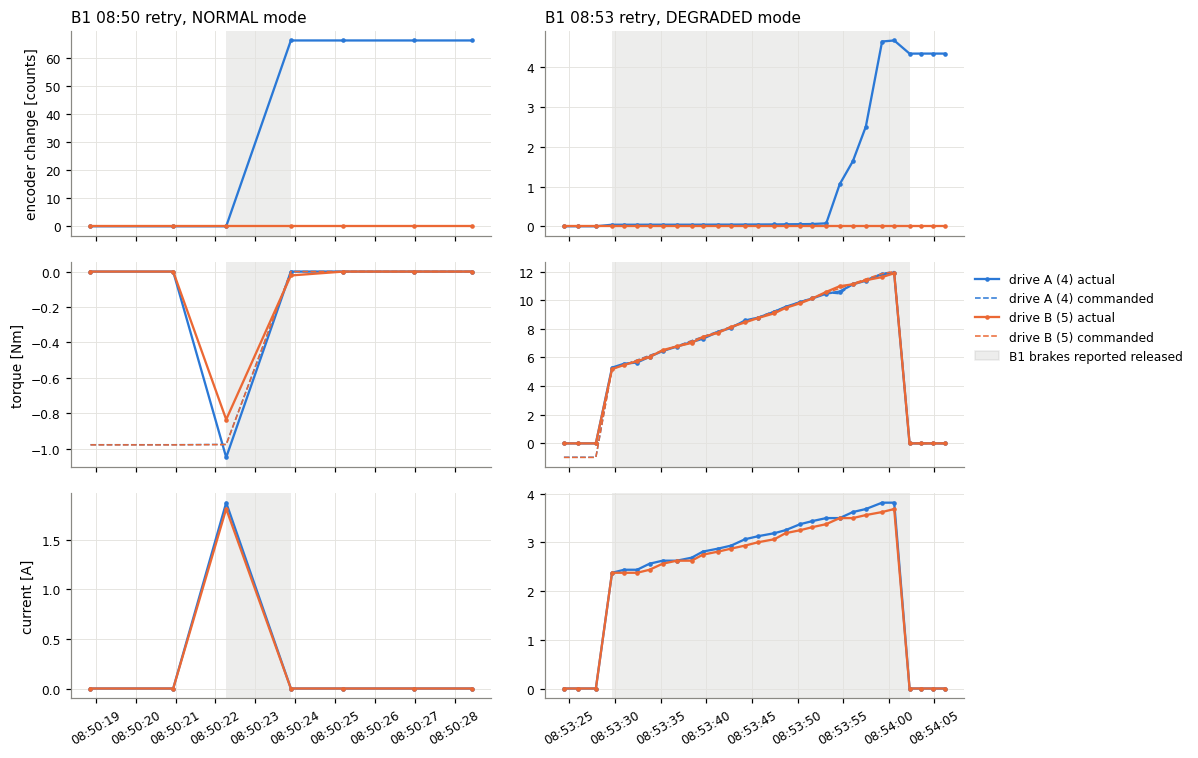

In [16]:
wins = [("08:50 retry, NORMAL mode", "2026-11-08 08:50:18", "2026-11-08 08:50:28"),
        ("08:53 retry, DEGRADED mode", "2026-11-08 08:53:24", "2026-11-08 08:54:06")]
fig, axs = plt.subplots(3, 2, figsize=(11, 7), sharex="col")
for k, (lab, t0, t1) in enumerate(wins):
    x = b1n.loc[t0:t1]
    for j, c, nm in [(4, C_A, "drive A (4)"), (5, C_B, "drive B (5)")]:
        e = x[f"encoderHeadCalibrated{j}"]
        axs[0, k].plot(x.index, e - e.iloc[0], ".-", color=c, ms=4, lw=1.5, label=nm)
        axs[1, k].plot(x.index, x[f"driveTorqueActual{j}"], ".-", color=c, ms=4, lw=1.5, label=f"{nm} actual")
        axs[1, k].plot(x.index, x[f"driveTorqueCommanded{j}"], ls="--", color=c, lw=1.0, label=f"{nm} commanded")
        axs[2, k].plot(x.index, x[f"driveCurrentActual{j}"], ".-", color=c, ms=4, lw=1.5, label=nm)
    for _, r in releases[(releases.engaged > pd.Timestamp(t0, tz="UTC")) &
                         (releases.released < pd.Timestamp(t1, tz="UTC"))].iterrows():
        for ax in axs[:, k]:
            ax.axvspan(r.released, r.engaged, color=C_GRAY, alpha=0.15, lw=0, zorder=0)
    axs[0, k].set_title(f"B1 {lab}", loc="left")
    axs[2, k].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    axs[2, k].tick_params(axis="x", rotation=30)
axs[0, 0].set_ylabel("encoder change [counts]"); axs[1, 0].set_ylabel("torque [Nm]"); axs[2, 0].set_ylabel("current [A]")
h = axs[1, 1].get_legend_handles_labels()[0] + [plt.Rectangle((0, 0), 1, 1, color=C_GRAY, alpha=0.15)]
axs[1, 1].legend(handles=h, labels=axs[1, 1].get_legend_handles_labels()[1] + ["B1 brakes reported released"],
                 frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout();

In [17]:
rs = cmds[cmds.kind == "resetDrivesLouvers"].copy()
def covered(det):
    d = {int(v) for v in det.split()}
    return " ".join(nm for i, nm in NAME.items() if {2 * i, 2 * i + 1} <= d) or "none"
rs["drives selected"] = rs.detail.map(lambda d: "all 68" if len(d.split()) == 68 else (d or "none"))
rs["active louvers fully reset"] = rs.detail.map(covered)
print("Every resetDrivesLouvers command since 2025-09 (reset[] is indexed by drive, 2i / 2i+1, not by louver):")
display(rs[["drives selected", "active louvers fully reset"]])

Every resetDrivesLouvers command since 2025-09 (reset[] is indexed by drive, 2i / 2i+1, not by louver):


,drives selected,active louvers fully reset
time,,
2026-06-19 21:00:25.798073+00:00,all 68,B1 E1 E2 H1 H2 M1
2026-06-19 21:03:45.894096+00:00,all 68,B1 E1 E2 H1 H2 M1
2026-06-19 21:09:44.523957+00:00,11,none
2026-06-19 22:14:44.018924+00:00,11,none
2026-06-19 22:23:00.541955+00:00,all 68,B1 E1 E2 H1 H2 M1
2026-06-19 22:28:41.541113+00:00,11,none
2026-06-20 16:37:33.444023+00:00,11,none
2026-06-20 16:39:37.957682+00:00,11,none
2026-06-21 10:15:52.179494+00:00,all 68,B1 E1 E2 H1 H2 M1


**Reading — answer to engineering.**
* **Drive B was enabled.** Whenever the brakes were released, drive B drew the same current as A: 1.8 A at the 08:50
  release, then 2.4 → 3.7 A in the DEGRADED retries. In those retries its actual torque followed its command to the
  12 Nm limit within ~0.1 Nm rms. The drive was powered and its current loop was working.
* **The B1 brake release was issued on five of the eleven close commands, but not on the first.**
  * **08:36.** The bit stayed engaged and B1 went straight to ERROR. B1's drives had been in FAULT since 02:02, and
    that fault wasn't cleared until the `exitFault` at 08:49.
  * **08:50, NORMAL mode.** Released for 1.6 s until the parallelism trip.
  * **08:53, 09:03, 09:16, 13:17, DEGRADED mode** (parallelism check bypassed). Released for ~32 s each, until
    torque saturation.
  * **09:15, 12:29, 13:09, NORMAL mode.** No release: the parallelism check tripped at once because A and B were
    already ~66 counts apart.
  * **12:40 and 12:42.** No release. The 12:40 command failed in the CSC with no motion. At 12:42 both drives were
    powered (1.8 A each) with the brake still engaged, which shows the ≈2 A enabled current also appears with the
    brake on.
* **What the EFD can't tell you:**
  * The bit is **one per louver**, covering both B1 brakes together. There is no per-drive brake signal.
  * ts_xml doesn't say whether the bit is the controller's commanded output or a brake-feedback contact.

  So *the release was commanded or reported*, but **the EFD can't prove that drive B's brake physically opened**.
  The louver controller's own log of brake output and brake feedback on drive B, or a brake-coil voltage check
  during a test move, would settle it.
* **Mechanical reading.** With A and B both at 12 Nm, A moved at most ~5 counts, and normal strokes move freely at
  4–6 Nm. So the B end of the blade was physically held. A dead drive-B encoder alone would not explain this, since
  the blade would still have moved. That leaves a **brake on drive B not opening, or a jam in the B actuator**.
* **Drive resets.** The only `resetDrivesLouvers` that night (12:39) selected **no drives**, so B1's drives 4/5 were
  never reset after the 02:02 drive fault; only `exitFault` was sent. In June, E1 resets selected **drive 11**, which
  looks like the louver index typed as a drive index (E1 = drives 22/23); all-drive resets did follow. Since drive B
  was clearly powered at 08:50, the missing reset probably did not cause the jam. Still, ts_xml notes that drives
  don't reset themselves when exiting FAULT outside DEGRADED mode.
* **Since the incident** (checked from the EFD on 2026-11-13; not in this notebook's caches): B1 has made full
  open/close strokes every night from 11-10 through 11-13, with both drives moving equally and no faults. Its A−B
  offset when closed is 8135.0–8136.0 counts, against 8135.7 before. The 85-min telemetry gap after the 13:22
  e-stop hides how it was recovered.

## 2. Stop-position drift

Stopped position after full strokes: **closed stop** (commanded 0) and **open stop** (commanded 100 — the louvers
stop at 95–98 %, each at its own repeatable value). A louver whose actuators are slipping or binding would be expected to
stop progressively short of, or beyond, its usual position.

Monthly median closed stop (%)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,-0.055,-0.058,-0.060,-0.082,-0.084,-0.087,-0.091,-0.089,-0.099,-0.093
E1,-0.062,-0.060,-0.078,-0.110,-0.107,-0.098,-0.105,-0.136,-0.135,-0.144
E2,-0.041,-0.046,-0.049,-0.065,-0.069,-0.069,-0.074,-0.076,-0.076,-0.071
H1,-0.056,-0.061,-0.068,-0.078,-0.077,-0.072,-0.073,-0.074,-0.071,-0.073
H2,-0.063,-0.067,-0.072,-0.082,-0.084,-0.085,-0.089,-0.092,-0.086,-0.089
M1,-0.138,-0.142,-0.149,-0.181,-0.174,-0.180,-0.182,-0.174,-0.177,-0.178


Monthly median open stop (%)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,96.37,96.68,96.74,96.63,96.41,96.47,96.26,96.52,96.11,96.14
E1,98.52,98.86,98.80,98.63,98.38,98.38,98.18,98.21,97.85,97.96
E2,96.28,96.62,96.69,96.49,96.25,96.31,96.07,96.14,95.89,95.98
H1,98.18,98.57,98.70,98.55,98.32,98.16,97.79,98.06,97.58,97.68
H2,98.43,98.89,98.92,98.86,98.63,98.71,98.42,98.48,98.17,98.33
M1,95.28,95.91,96.05,96.00,95.74,95.74,95.10,95.43,95.52,95.51


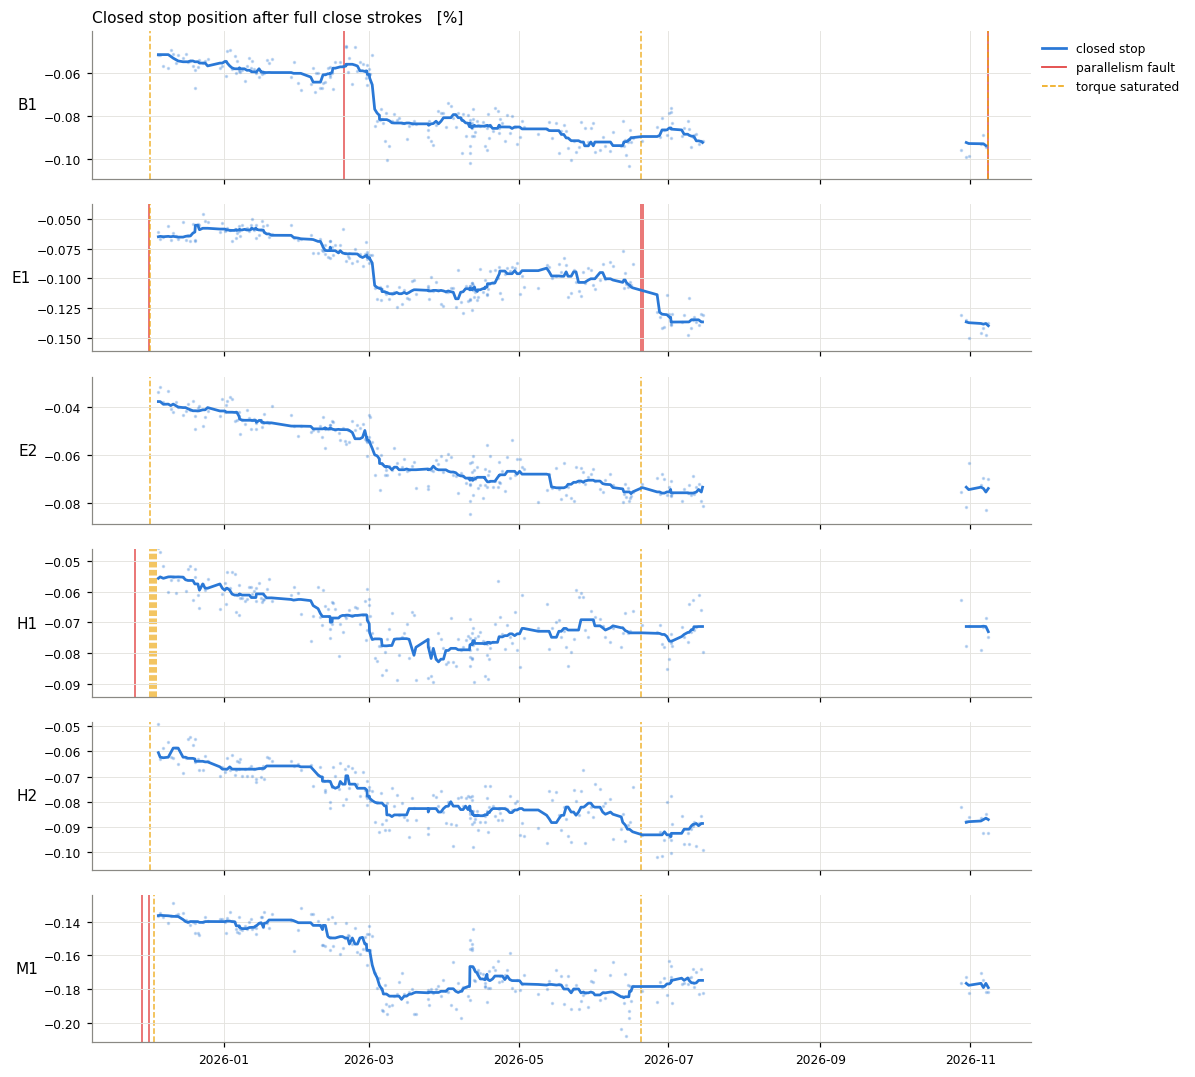

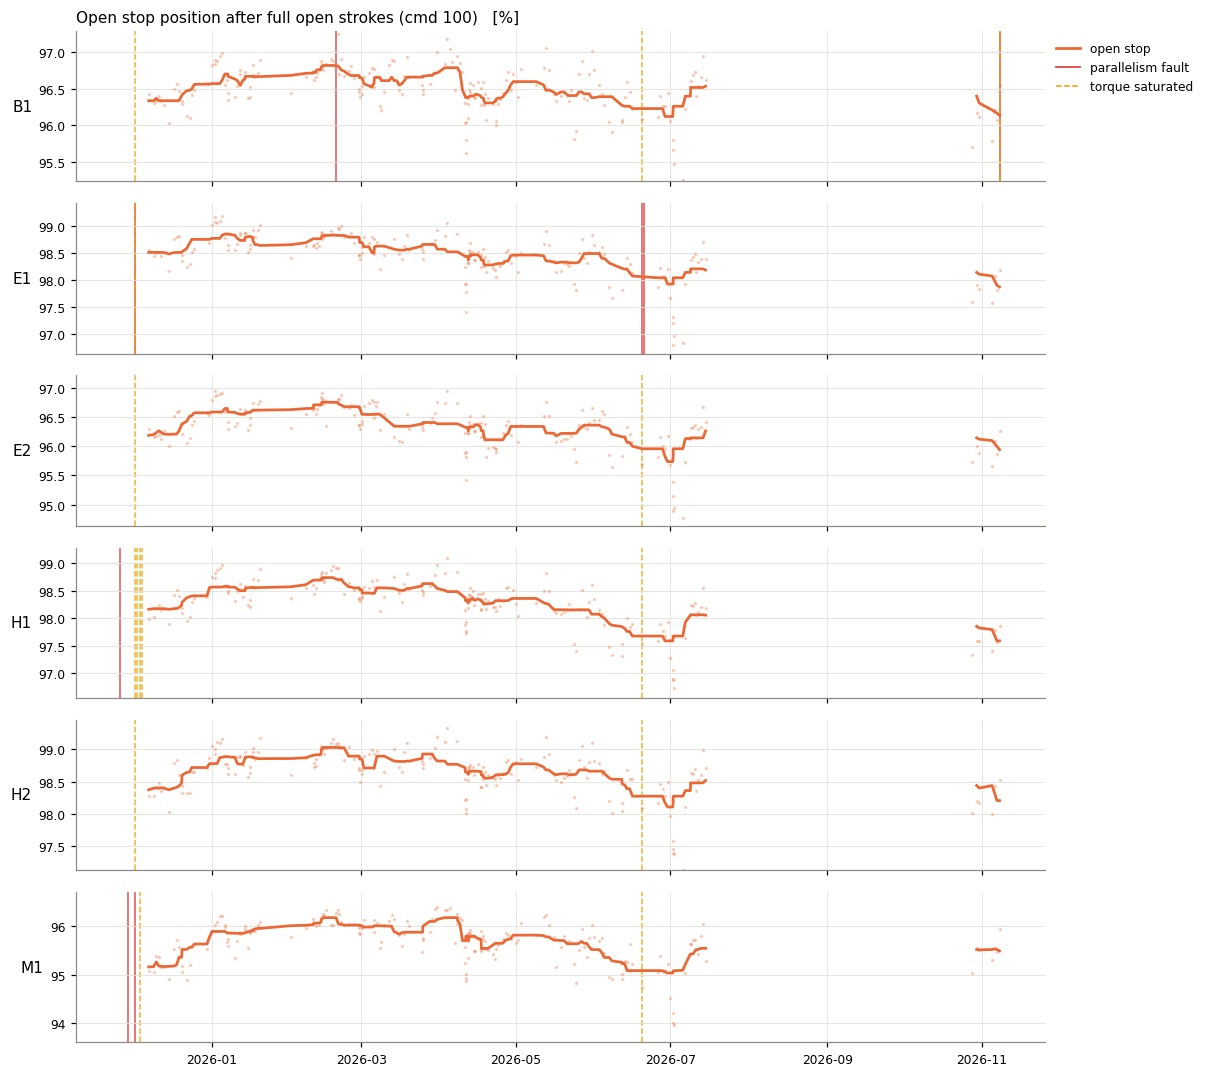

In [18]:
cl = full[(full.direction == "close") & (full.cmd_to == 0)]
op = full[(full.direction == "open") & (full.cmd_to == 100)]
stops = pd.concat([cl.assign(stop="closed"), op.assign(stop="open")])
stops["closed_pos"] = stops.pos_to.where(stops.stop == "closed")
stops["open_pos"] = stops.pos_to.where(stops.stop == "open")

per_louver(stops[stops.stop == "closed"], ["closed_pos"], "Closed stop position after full close strokes", "%",
           labels=["closed stop"], colors=(C_A,))
per_louver(stops[stops.stop == "open"], ["open_pos"], "Open stop position after full open strokes (cmd 100)", "%",
           labels=["open stop"], colors=(C_B,))

monthly = lambda d, v: d[d.t_start >= BASELINE_START].assign(m=d.t_start.dt.tz_localize(None).dt.to_period("M")) \
    .pivot_table(index="name", columns="m", values=v, aggfunc="median").loc[NAMES]
print("Monthly median closed stop (%)"); display(monthly(cl, "pos_to").round(3))
print("Monthly median open stop (%)");   display(monthly(op, "pos_to").round(2))

**Reading.** The closed stop creeps slowly more negative on every louver (≈ −0.04 to −0.09 % over the year; E1 the
largest). The open stop falls by 0.3–0.9 % on *all* louvers together, highest in austral summer (Dec–Feb) and lowest
Jun–Oct — consistent with a common-mode (thermal / structural) effect. Neither shows a louver-specific excursion ahead
of the B1 or E1 faults. Stop position is a weak failure indicator here, partly because `positionActual` averages the
two actuators and so hides their disagreement — see §3.

## 3. Actuator parallelism (A − B encoder offset)

* **Offset at rest** — `encA − encB` at the closed and open stops, relative to each louver's Dec 2025 median. A step or
  drift means one actuator has slipped relative to the other.
* **In-stroke excursion** — max |Δ(A−B)| during a full stroke, and the A vs B stroke-length mismatch. These measure how
  much of the controller's parallelism margin each louver uses on a normal stroke (the faults tripped at ≈65–75 counts).

Monthly median in-stroke A−B excursion, closing (counts)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,10.1,9.4,9.5,10.7,9.9,10.4,9.5,10.1,10.8,10.4
E1,34.6,34.0,35.3,35.6,36.6,37.3,38.1,37.2,39.8,39.1
E2,13.0,14.3,13.6,14.2,15.2,14.7,14.7,14.2,9.9,10.9
H1,31.9,32.5,33.1,33.9,34.0,34.9,35.6,34.6,34.7,34.7
H2,15.9,14.5,14.0,15.4,15.3,15.4,16.1,15.4,15.2,14.3
M1,43.2,43.1,44.3,44.2,42.7,41.8,41.5,40.1,42.2,41.7


Monthly median A−B offset at closed stop (counts)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,8135.1,8135.0,8134.7,8134.6,8134.9,8134.8,8134.3,8135.0,8135.1,8134.9
E1,3663.2,3664.4,3663.4,3661.9,3662.5,3664.0,3663.6,3659.3,3659.8,3659.6
E2,6457.3,6457.5,6457.5,6457.6,6457.7,6457.6,6457.2,6457.5,6457.6,6457.2
H1,6432.1,6432.1,6432.1,6432.4,6432.2,6432.2,6431.9,6431.7,6432.3,6431.9
H2,14727.1,14726.9,14727.3,14726.7,14726.8,14726.6,14726.7,14726.6,14727.8,14726.7
M1,26.8,26.5,26.8,26.3,26.3,26.0,26.2,26.0,26.0,26.1


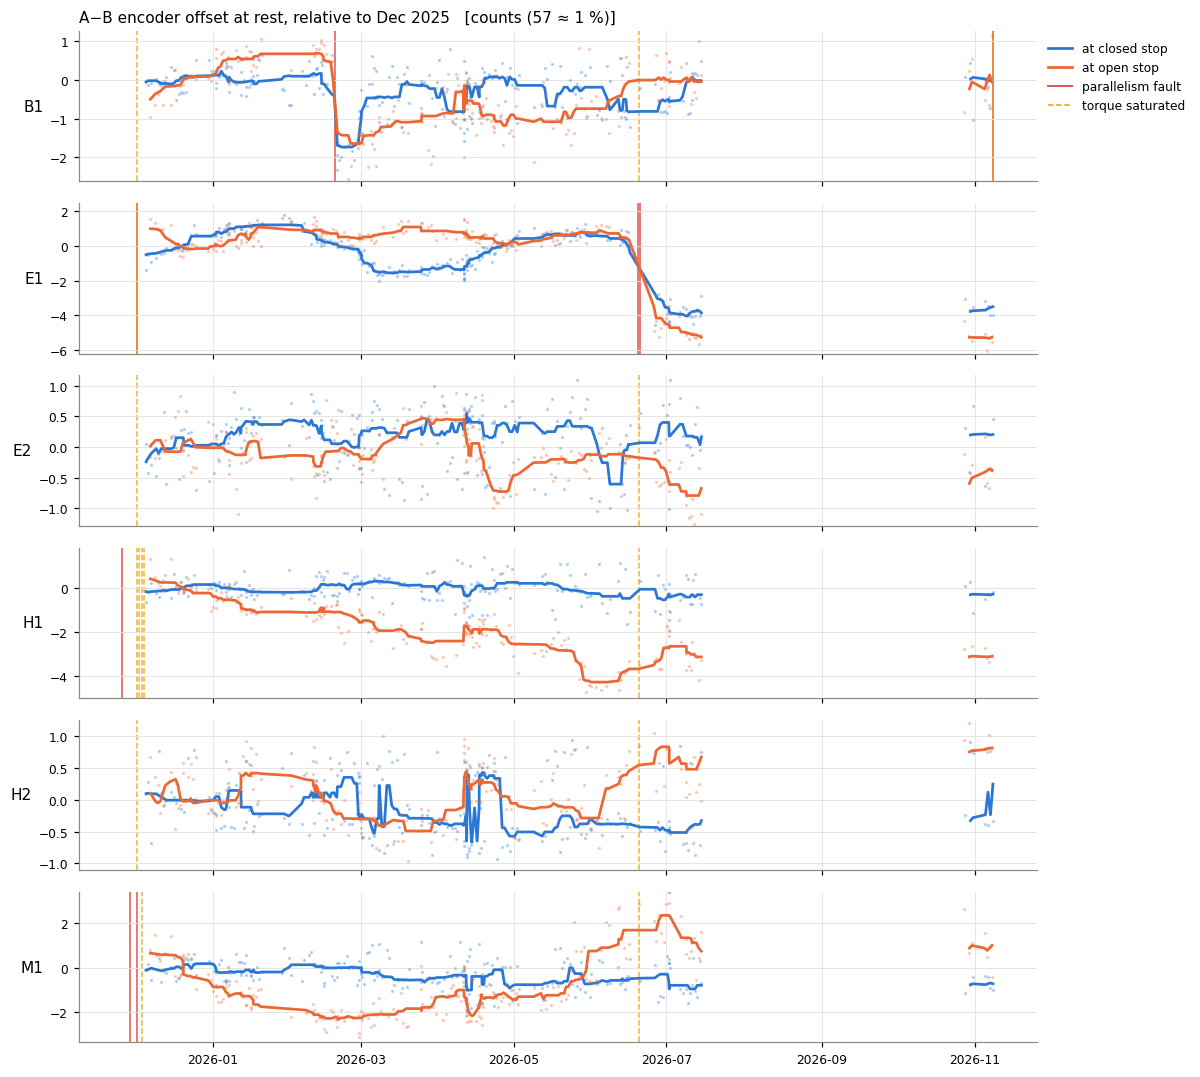

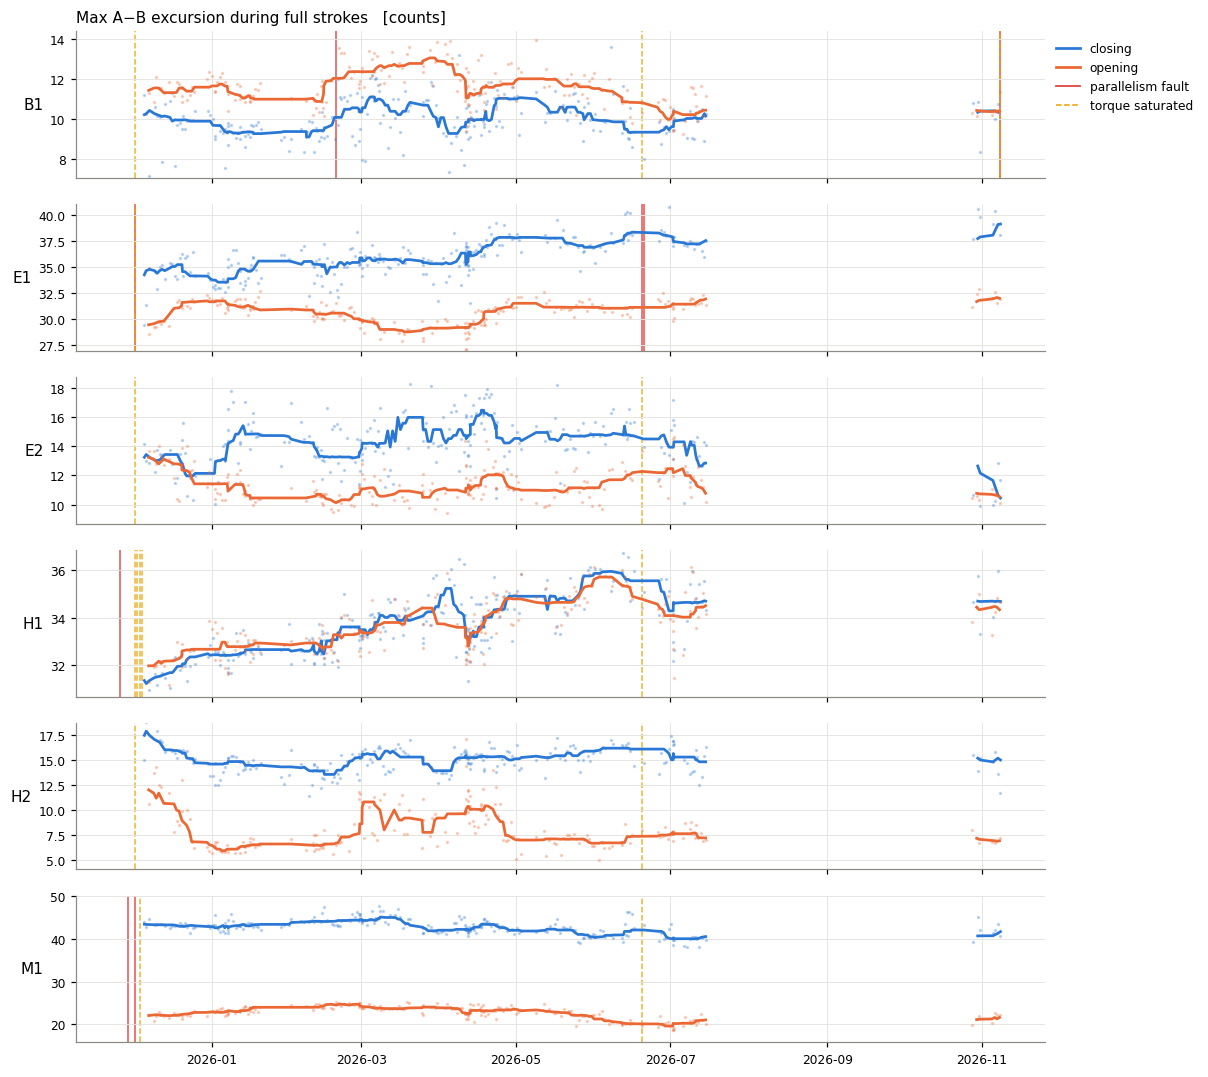

In [19]:
ref = lambda d: d.offset_after - d[d.t_start.between(BASELINE_START, BASELINE_START + pd.Timedelta("30D"))] \
    .groupby("name").offset_after.median().reindex(d.name).to_numpy()
cl2, op2 = cl.copy(), op.copy()
cl2["d_off"], op2["d_off"] = ref(cl2), ref(op2)
rest = pd.concat([cl2.assign(off_closed=cl2.d_off), op2.assign(off_open=op2.d_off)])
per_louver(rest, ["off_closed", "off_open"], "A−B encoder offset at rest, relative to Dec 2025", "counts (57 ≈ 1 %)",
           labels=["at closed stop", "at open stop"], ylim_q=(0.02, 0.98))

full_b = full[full.t_start >= BASELINE_START].copy()
per_louver(full_b.assign(dyn_close=full_b.offset_dyn_max.where(full_b.direction == "close"),
                         dyn_open=full_b.offset_dyn_max.where(full_b.direction == "open")),
           ["dyn_close", "dyn_open"], "Max A−B excursion during full strokes", "counts",
           labels=["closing", "opening"], ylim_q=(0.02, 0.98))

print("Monthly median in-stroke A−B excursion, closing (counts)"); display(monthly(cl, "offset_dyn_max").round(1))
print("Monthly median A−B offset at closed stop (counts)");      display(monthly(cl, "offset_after").round(1))

**Reading.** At rest, the offsets are stable to about ±1 count for B1, E2, H2 and M1. **E1 steps by −4 to −6 counts after
its June 19–20 fault** and H1's open-stop offset drifts ≈ −4 counts. In-stroke excursion is very different per louver:
B1 ≈ 10, E2/H2 ≈ 10–15, H1 ≈ 35, M1 ≈ 42, **E1 ≈ 32 → 39–40 counts and rising** (closing). E1 and H1 both grew through
H1 2026; M1 is large but steady. B1 — which faulted twice — has the *smallest* excursion, so the margin used on a normal
stroke does not by itself predict the abrupt "B does not start" failure.

## 4. Drive-B onset lag — the failure-mode precursor

The 2026 parallelism faults began with drive B's side not moving at the start of a stroke (§1.4). A partially-sticking drive B
(brake not fully released, binding) should first appear as B *trailing* A in the first seconds of otherwise normal
strokes. `excess_lag` = (|ΔA| − |ΔB|) over the first ~3 s, minus the part explained by the louver's fixed encoder-scale
mismatch (`k_scale`). Positive = B behind A.

Monthly median excess onset lag, open (counts)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,1.4,1.5,1.8,2.3,2.0,1.9,1.0,0.6,0.6,0.6
E1,-0.1,0.4,2.0,1.4,1.1,2.3,3.6,4.5,6.3,4.8
E2,-6.9,-4.4,-2.2,-4.0,-4.4,-3.3,-4.6,-3.5,-0.6,-1.2
H1,-7.9,-7.7,-6.9,-6.7,-8.5,-7.3,-7.0,-7.0,-8.7,-8.0
H2,-2.1,-0.4,-0.7,-3.1,-4.1,-2.3,-3.2,-3.6,-2.1,-2.6
M1,10.8,11.2,11.1,11.4,10.2,10.5,10.1,10.6,11.5,12.6


Monthly median excess onset lag, close (counts)


m,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
name,,,,,,,,,,
B1,-4.0,-4.1,-3.1,-5.5,-5.6,-2.5,-5.0,-6.4,-1.6,-1.8
E1,1.8,-0.2,0.8,2.5,2.9,4.4,3.7,3.5,7.6,2.4
E2,-3.7,-4.0,-4.3,-9.0,-6.5,-6.1,-6.0,-4.9,-6.4,-3.6
H1,-5.0,-5.5,-6.1,-4.2,-5.9,-3.5,-1.9,-2.9,-2.9,-2.7
H2,1.7,1.2,0.6,0.1,-0.1,0.1,0.5,-0.1,0.5,0.0
M1,15.0,13.0,13.2,12.9,12.5,10.4,10.8,11.2,14.0,13.3


E1 onsets per month: {Period('2025-12', 'M'): 95, Period('2026-01', 'M'): 117, Period('2026-02', 'M'): 148, Period('2026-03', 'M'): 136, Period('2026-04', 'M'): 168, Period('2026-05', 'M'): 91, Period('2026-06', 'M'): 76, Period('2026-07', 'M'): 55, Period('2026-10', 'M'): 20, Period('2026-11', 'M'): 18}


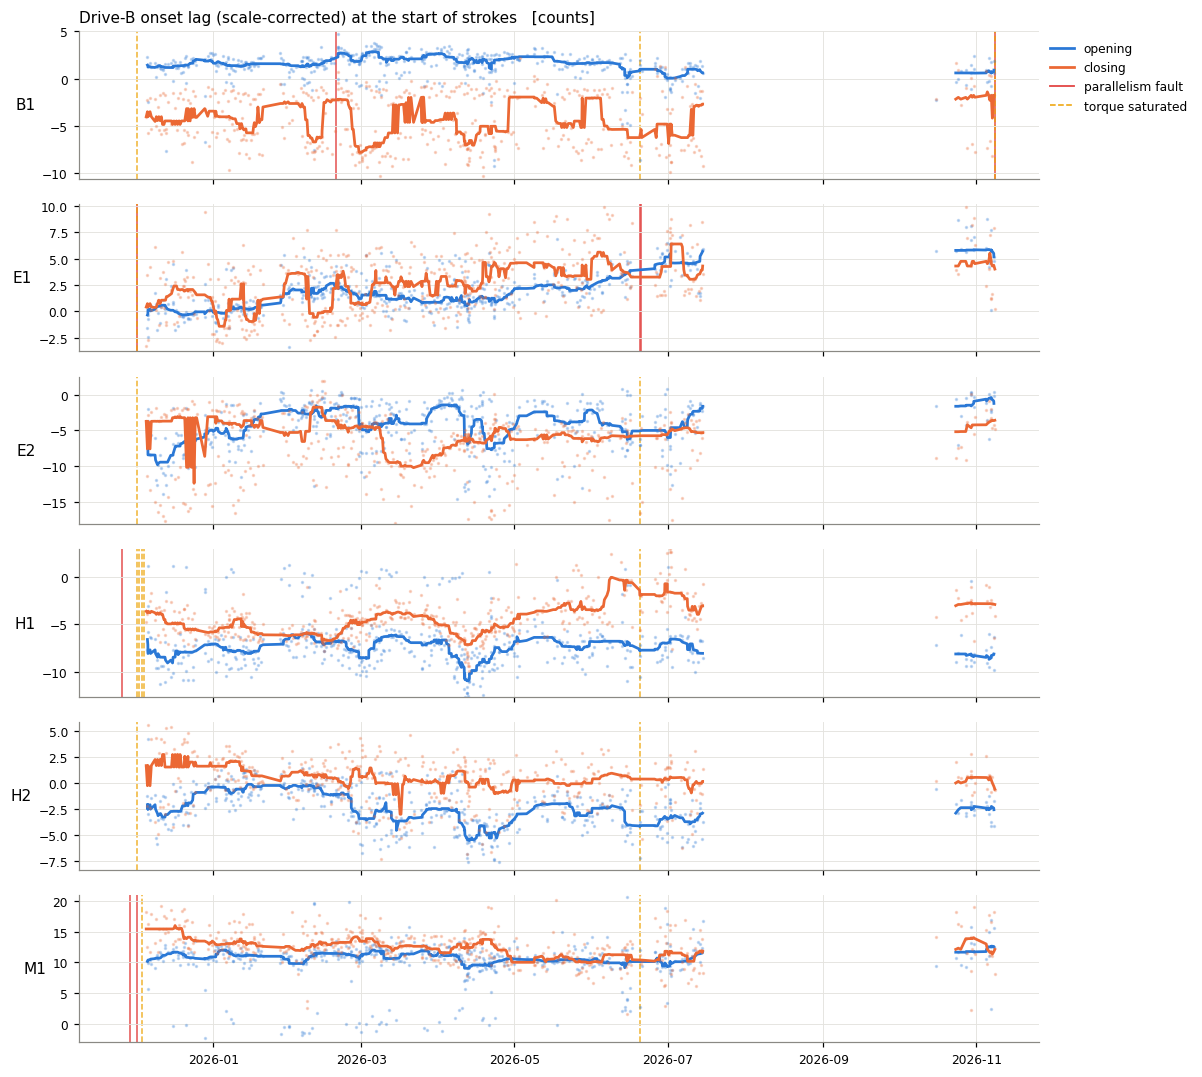

In [20]:
onb = on_ok.rename(columns={"t": "t_start"})
per_louver(onb.assign(lag_open=onb.excess_lag.where(onb.direction == "open"),
                      lag_close=onb.excess_lag.where(onb.direction == "close")),
           ["lag_open", "lag_close"], "Drive-B onset lag (scale-corrected) at the start of strokes", "counts",
           labels=["opening", "closing"], ylim_q=(0.02, 0.98), n=21)

onm = on_ok[on_ok.t >= BASELINE_START].assign(m=lambda d: d.t.dt.tz_localize(None).dt.to_period("M"))
for d in ["open", "close"]:
    print(f"Monthly median excess onset lag, {d} (counts)")
    display(onm[onm.direction == d].pivot_table(index="name", columns="m", values="excess_lag", aggfunc="median")
            .loc[NAMES].round(1))
print("E1 onsets per month:", onm[onm.name == "E1"].groupby("m").size().to_dict())

**Reading.** E1 is the only louver with a sustained rise: from ≈0 counts in Dec 2025 to ≈5–8 counts by Oct–Nov 2026,
in **both** directions (so it is not a load/gravity asymmetry), and it kept rising after the June fault. M1 carries a
large but constant lag (~11–13 counts) — a fixed characteristic, not a trend. B1's lag is flat: its 2026-02 and
2026-11 failures were abrupt. Statistics thin out in Oct–Nov (≈20 E1 strokes per month).

## 5. Torque, current and stroke duration

Mean |torque| and mean current per drive during full strokes (closing and opening separately, since gravity/wind
load differs), torque tracking error (RMS actual − commanded), and stroke duration.

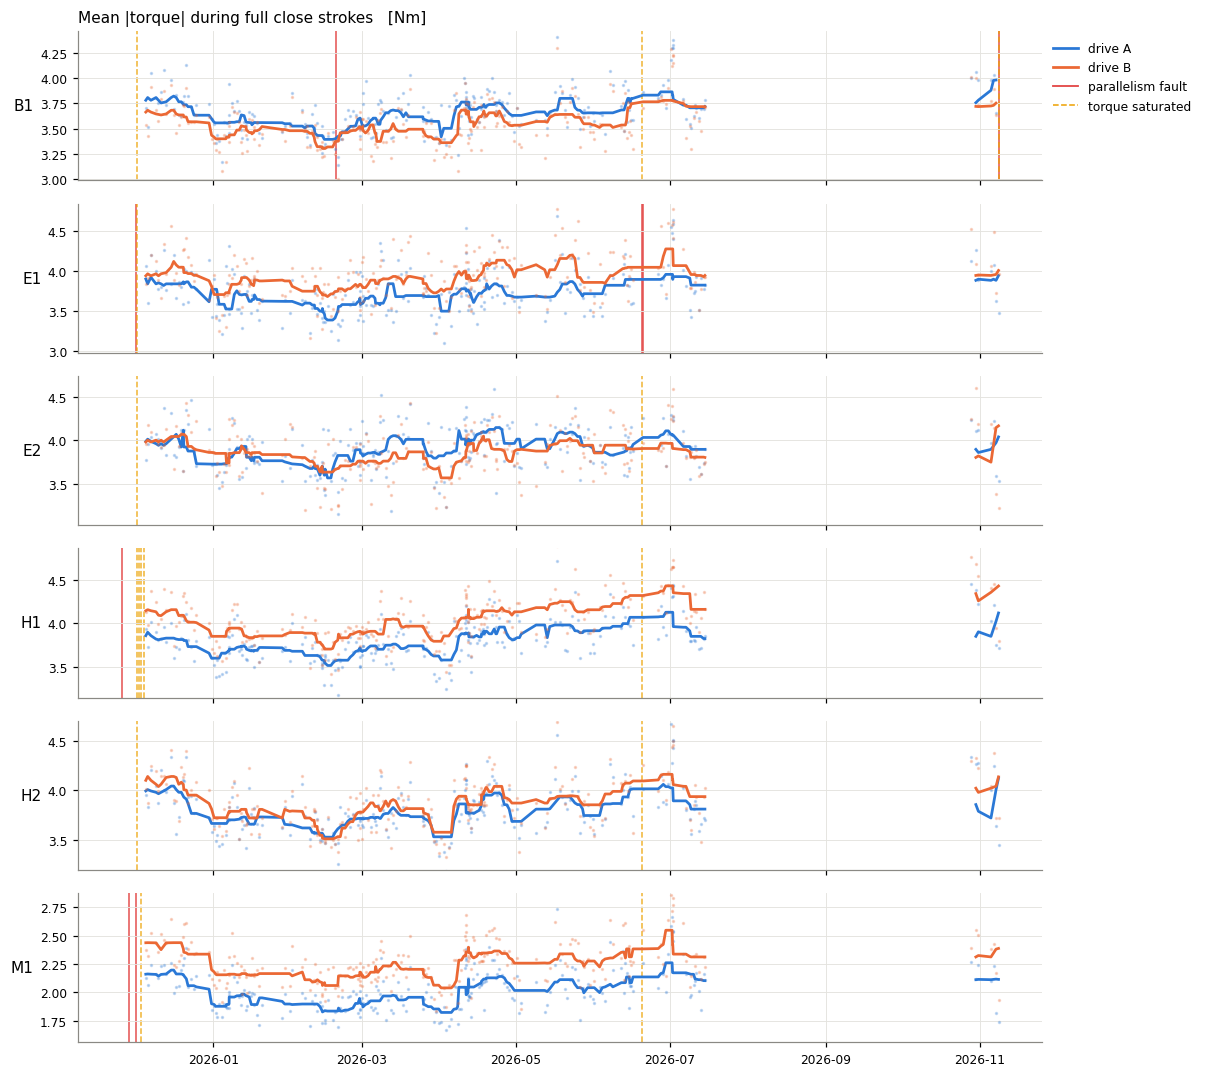

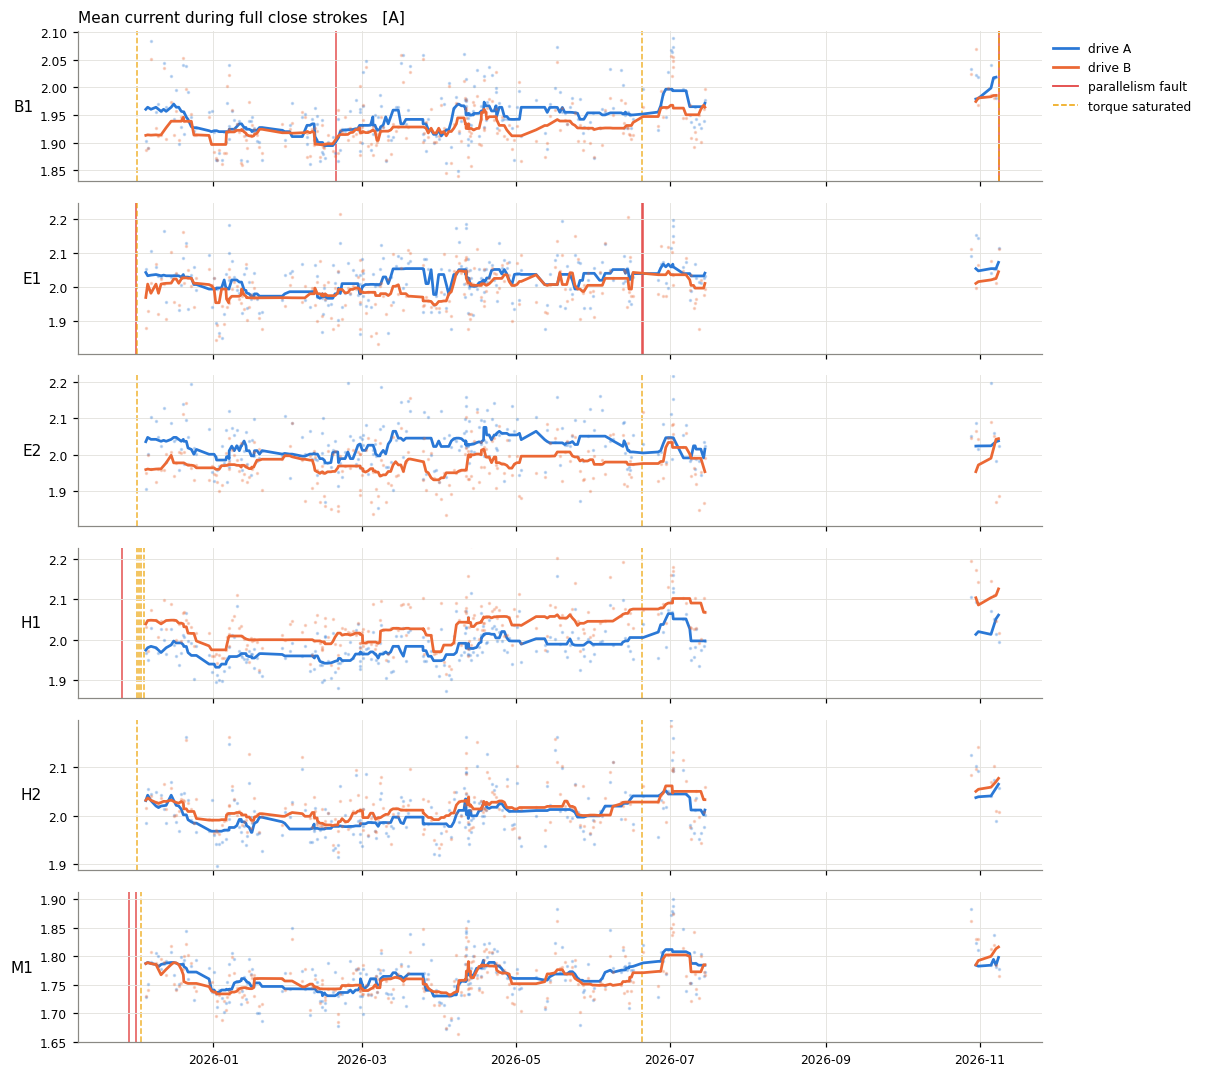

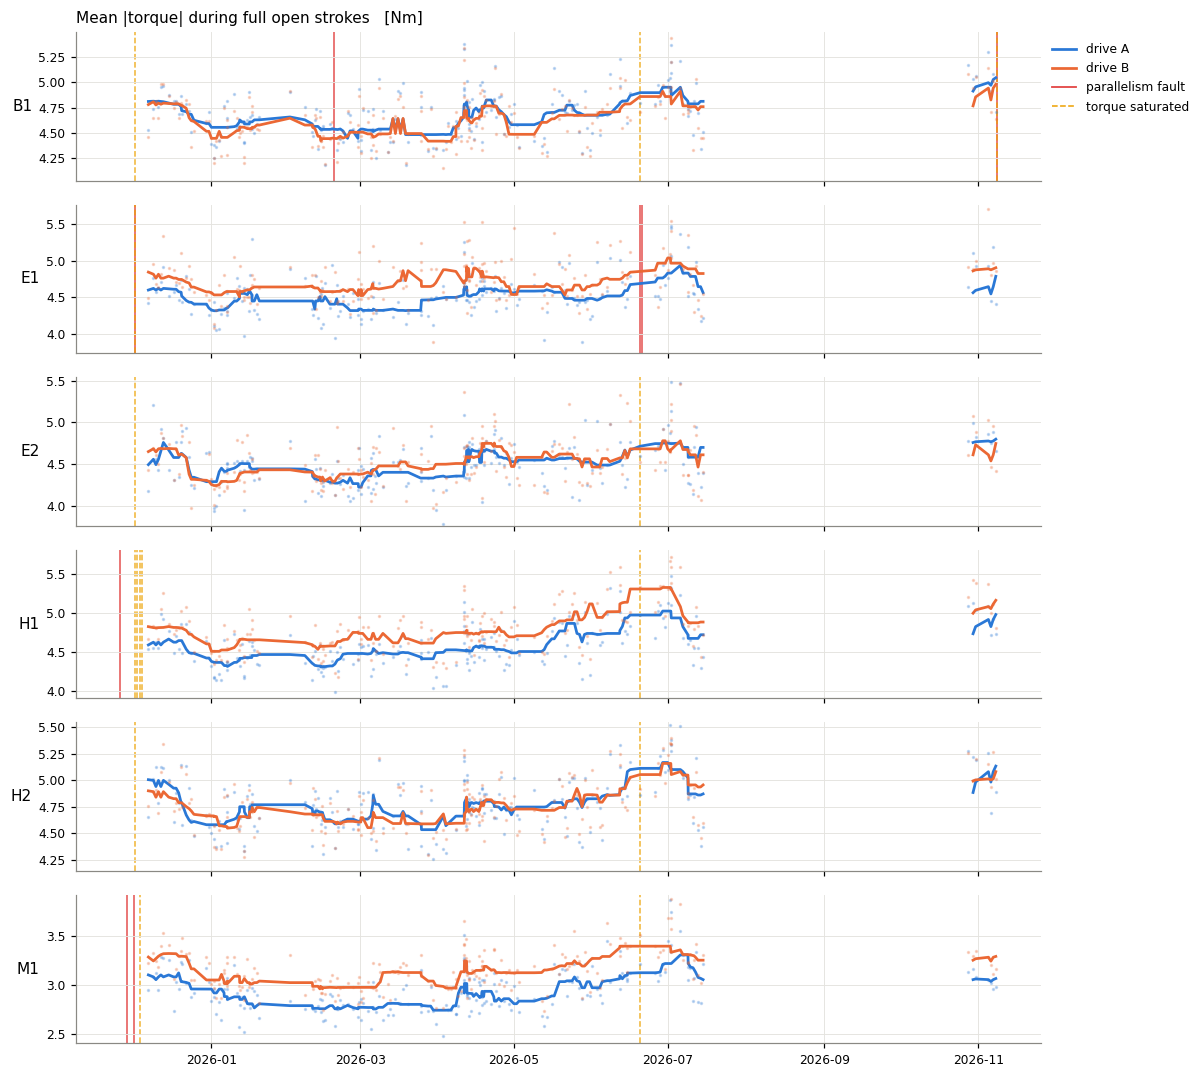

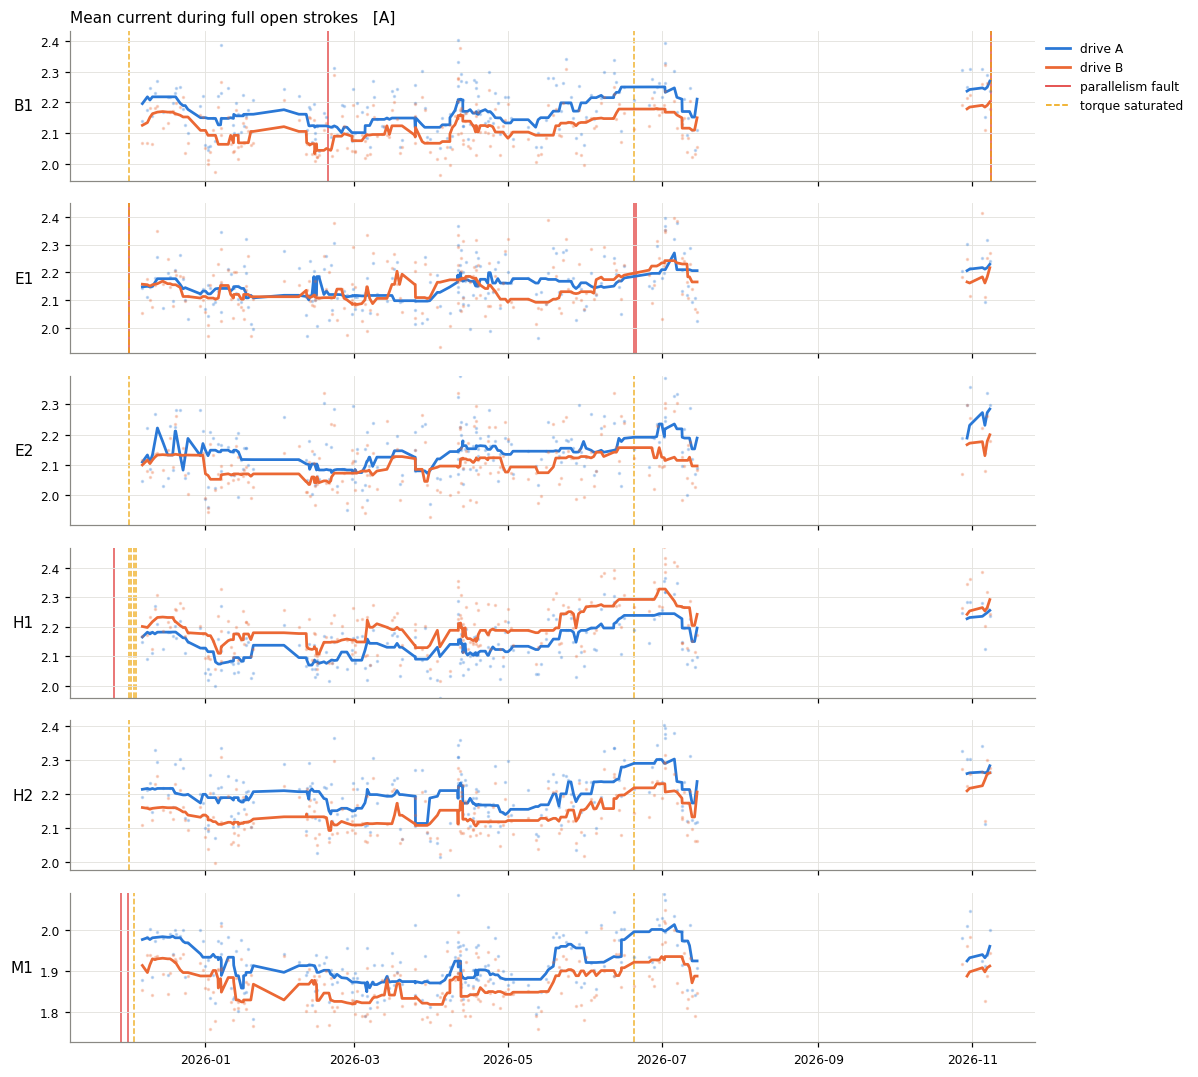

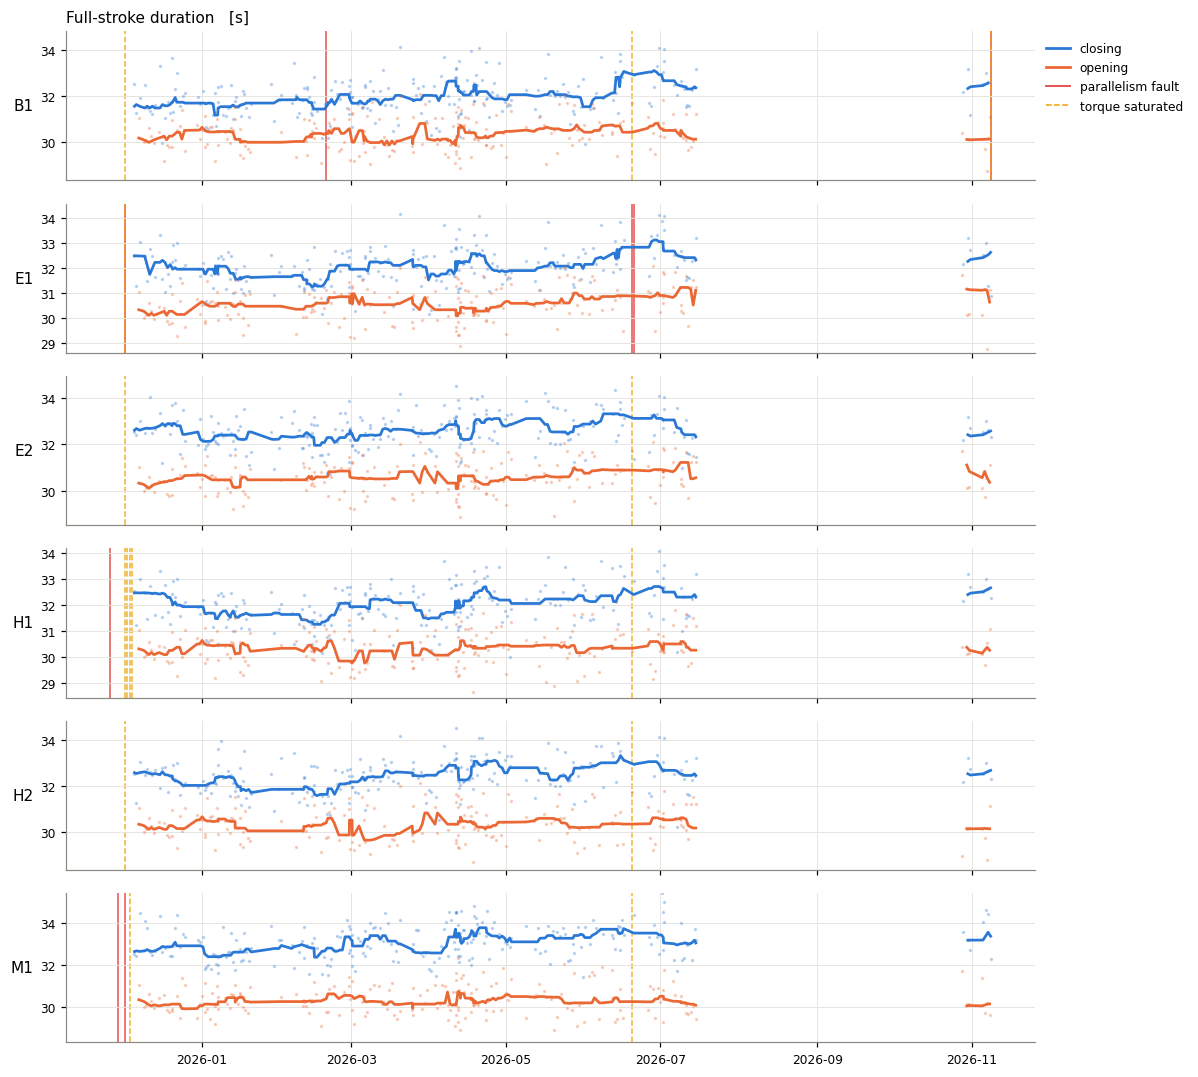

In [21]:
for d in ["close", "open"]:
    x = full_b[full_b.direction == d]
    per_louver(x, ["tq_mean_a", "tq_mean_b"], f"Mean |torque| during full {d} strokes", "Nm",
               labels=["drive A", "drive B"])
    per_louver(x, ["cur_mean_a", "cur_mean_b"], f"Mean current during full {d} strokes", "A",
               labels=["drive A", "drive B"])
per_louver(full_b.assign(dur_close=full_b.duration_s.where(full_b.direction == "close"),
                         dur_open=full_b.duration_s.where(full_b.direction == "open")),
           ["dur_close", "dur_open"], "Full-stroke duration", "s", labels=["closing", "opening"]);

**Reading.** Torque and current drift up slowly on **every** louver (≈ +6–10 % torque, +3–5 % current since Dec 2025,
October highest) and closing strokes take ~1.5 s longer (M1 the slowest at ~34 s). Drives A and B on the same louver
track each other closely, and no louver departs from the common trend before its faults. This argues for an
environmental / common cause (temperature, grease viscosity, dome structure) rather than a single degrading actuator —
worth correlating with dome air temperature in a follow-up.

## 6. Trend summary

Theil–Sen slope per 30 days for each metric, louver and direction, from `BASELINE_START` (2025-12-05) to now, plus the
first-30-day vs last-60-day median change. Robust to the occasional outlier stroke. `|Δ|/σ` compares the change with
the stroke-to-stroke scatter (MAD-based σ over the baseline month) — values ≳ 1 are worth attention.

In [22]:
def trend_rows(df, tcol, metrics, group="direction"):
    out = []
    for (nm, g), x in df[df[tcol] >= BASELINE_START].groupby(["name", group]):
        x = x.sort_values(tcol)
        tdays = (x[tcol] - BASELINE_START).dt.total_seconds() / 86400
        first = x[x[tcol] < BASELINE_START + pd.Timedelta("30D")]
        last = x[x[tcol] > x[tcol].max() - pd.Timedelta("60D")]
        for met in metrics:
            y = x[met].to_numpy(); good = np.isfinite(y)
            if good.sum() < 20 or len(first) < 5 or len(last) < 5:
                continue
            slope = theilslopes(y[good], tdays.to_numpy()[good])[0] * 30
            sig = 1.4826 * np.nanmedian(np.abs(first[met] - first[met].median()))
            delta = last[met].median() - first[met].median()
            out.append(dict(louver=nm, dir=g, metric=met, n=int(good.sum()),
                            dec2025=first[met].median(), last60d=last[met].median(), delta=delta,
                            slope_per_30d=slope, delta_over_sigma=delta / sig if sig > 0 else np.nan))
    return pd.DataFrame(out)

tr = pd.concat([
    trend_rows(full, "t_start", ["pos_to", "offset_after", "offset_dyn_max", "mismatch",
                                 "tq_mean_a", "tq_mean_b", "cur_mean_a", "cur_mean_b",
                                 "tq_err_a", "tq_err_b", "duration_s"]),
    trend_rows(on_ok.rename(columns={"t": "t_start"}), "t_start", ["excess_lag"]),
], ignore_index=True)
tr["louver"] = pd.Categorical(tr.louver, NAMES)
summary = tr.pivot_table(index=["metric", "dir"], columns="louver", values="delta", observed=False)
print("Change, last 60 days vs Dec 2025 (metric units; counts for offsets/lag, % for pos_to, Nm, A, s)")
display(summary.round(2))
print("Change in units of baseline stroke-to-stroke scatter (|Δ|/σ ≳ 1 highlighted)")
z = tr.pivot_table(index=["metric", "dir"], columns="louver", values="delta_over_sigma", observed=False)
display(z.round(1).style.map(lambda v: "background-color:#fbe3e2" if np.isfinite(v) and abs(v) >= 1 else ""))

Change, last 60 days vs Dec 2025 (metric units; counts for offsets/lag, % for pos_to, Nm, A, s)


louver                  B1    E1    E2    H1    H2    M1
metric         dir                                      
cur_mean_a     close  0.07  0.06  0.03  0.10  0.07  0.03
               open   0.10  0.10  0.16  0.11  0.10  0.01
cur_mean_b     close  0.07  0.06  0.08  0.11  0.06  0.06
               open   0.07  0.12  0.10  0.13  0.11  0.02
duration_s     close  0.91  0.54  0.02  0.55  0.26  0.69
               open  -0.07 -0.04 -0.31 -0.04 -0.08  0.04
excess_lag     close  2.26  3.17 -0.51  2.49 -1.09 -0.47
               open  -0.86  5.88  5.69 -0.46 -0.52  0.87
mismatch       close  0.54  1.57  0.49  2.82 -1.10 -0.87
               open  -0.21  0.60  0.85  1.96 -0.99 -0.10
offset_after   close -0.09 -3.54  0.22 -0.25 -0.23 -0.76
               open  -0.23 -5.32 -0.36 -3.09  0.82  0.87
offset_dyn_max close  0.60  4.93 -2.65  2.73 -0.91 -1.09
               open  -1.10  0.74 -1.91  2.12 -2.13 -0.44
pos_to         close -0.04 -0.08 -0.03 -0.01 -0.02 -0.04
               open  -0.32 -0.70 -0.49 -0.68 -0.34  0.07
tq_err_a       close  0.07  0.05  0.00  0.07  0.06  0.05
               open  -0.01 -0.12 -0.01  0.06 -0.07  0.09
tq_err_b       close  0.01  0.33  0.31  0.05  0.02  0.02
               open   0.06 -0.00 -0.03  0.04 -0.11  0.01
tq_mean_a      close  0.26  0.18  0.19  0.41  0.32 -0.01
               open   0.35  0.44  0.33  0.50  0.46  0.03
tq_mean_b      close  0.24  0.10  0.23  0.41  0.23  0.04
               open   0.37  0.23  0.34  0.46  0.39  0.05

Change in units of baseline stroke-to-stroke scatter (|Δ|/σ ≳ 1 highlighted)


## 7. Conclusions and suggested monitoring

* **Failure mode.** The 2026 parallelism faults (B1 Feb and Nov, E1 Jun) all began with the B (odd-index) drive's end
  of the blade not moving while A moved ≈1.2 %, even though drive B was powered and pushing (up to 12 Nm, 3.7 A) and,
  on 11-08, the B1 brake release was commanded. That points to **drive B's brake not opening physically, or a B-side
  jam**. The Nov–Dec 2025 faults were a different mode (both moving, A outruns B by ~10–20 counts). Neither is a slow
  drift of the stopped position, and `positionActual` averages the two drives and can't see them.
* **Next diagnostic for B1.** The EFD has only one brake bit per louver and doesn't say whether it is command or
  feedback. Check drive B's brake output and feedback in the louver controller logs, or measure the brake-coil voltage
  during a test move, before a mechanical intervention. Make sure drive resets name the right drives (2i, 2i+1).
* **Precursor.** The quantity that *does* trend ahead of trouble is the **drive-B onset lag** (and, more weakly, the
  in-stroke A−B excursion). **E1** shows a steady year-long rise in both and is the most likely next failure; it should
  be inspected (drive-B brake release, coupling, binding) before it trips again. H1's in-stroke excursion has also grown
  (≈31 → 35 counts) and it has the most drive-fault days (37) — second on the watch list.
* **B1** jammed at ~96 % open from 08:50 to the on-site recovery (closed and re-synchronised by 14:51 UTC). Its failures
  (Feb and Nov) came without a gradual stroke-telemetry signature, so the drive-fault flag and inspection of drive B
  (brake release, enable chain) matter more than trend monitoring there. The repeated 30 s `setLouvers` re-sends that drive
  louvers into the open hard stop with 7–11 Nm pulses and twist the blade are a plausible stressor and worth raising
  with the dome/SAL script owners.
* **Common-mode drifts** in open stop, torque, current and closing duration affect all six louvers together; correlate
  with dome temperature before reading them as wear.

**Monitoring rule of thumb** (counts, ≈57 per 1 %): per-stroke `excess_lag` rolling median > 8, or in-stroke
A−B excursion > 45 (≈ 65 % of the ~70-count trip level), or any onset with |ΔB| < 2 while |ΔA| > 30.

*Refresh*: edit `T_END`/`TAG` in [build_louver_health.py](build_louver_health.py), run
`python3 -E build_louver_health.py` from this folder, then update `TAG` above and re-run.